# Kimi Delta Attention (KDA): linear attention with a delta rule and channel-wise forgetting

Kimi Delta Attention is the token mixer at the heart of **Kimi Linear** (Moonshot AI, 2025). It is a *linear attention*: instead of a KV cache that grows with every token, each head carries a **fixed-size matrix memory** $S \in \mathbb{R}^{d_k \times d_v}$ and updates it once per token:

$$S_t = \big(I - \beta_t k_t k_t^\top\big)\,\mathrm{Diag}(\alpha_t)\,S_{t-1} + \beta_t k_t v_t^\top, \qquad o_t = S_t^\top q_t$$

Each piece of this equation fixes a specific weakness of plain linear attention, and the notebook works through them one at a time:
* $k_t v_t^\top$: **write** the new key→value association (linear attention).
* $(I - \beta_t k_t k_t^\top)$: before writing, **erase** what the memory currently stores under $k_t$ (the *delta rule*, DeltaNet).
* $\mathrm{Diag}(\alpha_t)$: **forget**, with a separate data-dependent decay rate for **every key channel** (the KDA contribution; Gated DeltaNet uses a single scalar per head).

Kimi Linear interleaves 3 KDA layers with 1 full-attention (MLA) layer. The paper reports that this hybrid outperforms full MLA while *"reducing KV cache usage by up to 75% and achieving up to 6× decoding throughput for a 1M context"*.

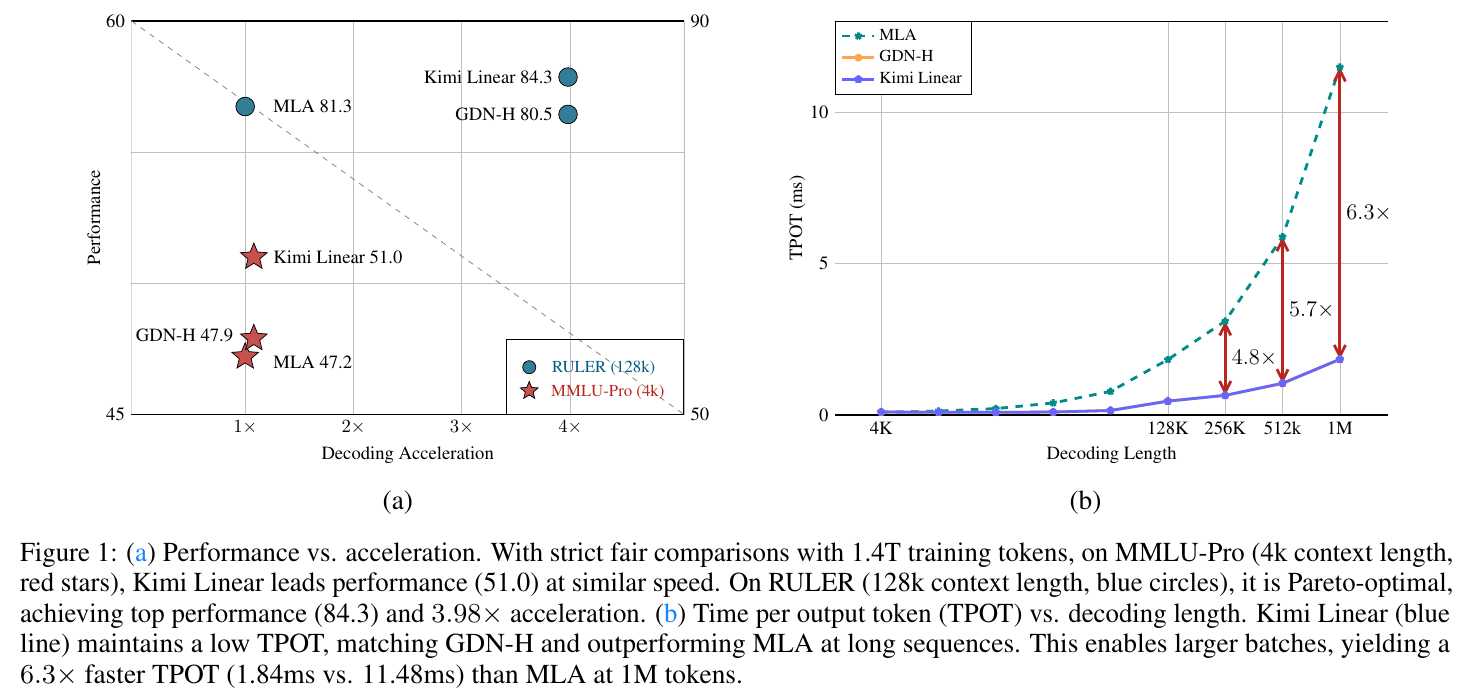

*Kimi Linear, Figure 1: (a) quality vs decoding speed for models trained identically on 1.4T tokens; (b) time per output token as the context grows. Full attention (MLA) slows down with every token in context, while the KDA hybrid stays nearly flat. Source: [Kimi Linear, arXiv:2510.26692](https://arxiv.org/abs/2510.26692), CC BY-NC-ND 4.0.*

We will build KDA from scratch in the following steps:
1. From softmax attention to linear attention with a fixed-size state
2. The problem with additive memory, and the delta rule
3. The delta rule as one step of online gradient descent
4. Forgetting: from a scalar gate (Gated DeltaNet) to channel-wise gates (KDA)
5. A reference recurrent implementation
6. The chunkwise-parallel algorithm (WY representation + UT transform), derived and verified
7. The full KDA layer (short convolutions, L2-normalized q/k, low-rank gates, gated RMSNorm)
8. Kimi Linear: the 3:1 KDA/MLA hybrid and its memory footprint
9. A small experiment: associative recall when keys get overwritten

Prerequisites in this repo: `25_multi_head_latent_attention.ipynb` (the MLA half of Kimi Linear), `09_multi_head_attention.ipynb`, `d_state_space.ipynb`.

### References
* Kimi Linear: An Expressive, Efficient Attention Architecture: https://arxiv.org/abs/2510.26692 (KDA is §3–4, Eq. 1–9)
* Parallelizing Linear Transformers with the Delta Rule over Sequence Length (DeltaNet): https://arxiv.org/abs/2406.06484
* Gated Delta Networks: Improving Mamba2 with Delta Rule: https://arxiv.org/abs/2412.06464
* Linear Transformers Are Secretly Fast Weight Programmers: https://arxiv.org/abs/2102.11174
* Reference kernels and layers: flash-linear-attention (`fla/ops/kda`, `fla/layers/kda.py`): https://github.com/fla-org/flash-linear-attention

In [1]:
import math
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

torch.manual_seed(0)

# ---- Plot style shared by every figure in this notebook ----
# Categorical colors are assigned in a fixed order (never cycled), grids are recessive,
# lines are thin, and series are direct-labeled where it helps.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = PALETTE
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#9a9893"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "xtick.color": INK_2, "ytick.color": INK_2,
    "lines.linewidth": 2, "lines.markersize": 6, "legend.frameon": False, "font.size": 10,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
})

# 1. From softmax attention to a fixed-size state

Causal softmax attention computes $o_t = \sum_{j \le t} \mathrm{softmax}_j(q_t^\top k_j)\, v_j$. Every output needs every past key and value, so the cache grows as $O(t)$ and the total cost is $O(T^2 d)$.

**Linear attention** drops the softmax (keeping only a feature map / normalization on $q, k$). Then the sum can be re-associated:

$$o_t = \sum_{j \le t} (q_t^\top k_j)\, v_j = \Big(\sum_{j \le t} v_j k_j^\top\Big) q_t = S_t^\top q_t, \qquad S_t = S_{t-1} + k_t v_t^\top \in \mathbb{R}^{d_k \times d_v}$$

The whole past is summarized in one $d_k \times d_v$ matrix per head, so decoding costs $O(d_k d_v)$ per token **no matter how long the context is**. The same computation also has a parallel (training) form, $O = (QK^\top \odot M)V$ with a causal mask $M$. Both forms must agree:

In [2]:
B, T, d_k, d_v = 2, 12, 8, 5
q, k, v = torch.randn(B, T, d_k), torch.randn(B, T, d_k), torch.randn(B, T, d_v)

# Parallel form: (Q K^T ⊙ causal mask) V
causal = torch.ones(T, T).tril()
o_parallel = ((q @ k.transpose(-1, -2)) * causal) @ v                    # (B, T, d_v)

# Recurrent form: S_t = S_{t-1} + k_t v_t^T,  o_t = S_t^T q_t
S = torch.zeros(B, d_k, d_v)
o_recurrent = []
for t in range(T):
    S = S + k[:, t, :, None] * v[:, t, None, :]                          # rank-1 write
    o_recurrent.append(torch.einsum("bk,bkv->bv", q[:, t], S))           # read with the query
o_recurrent = torch.stack(o_recurrent, 1)
print(f"parallel vs recurrent linear attention: max |diff| = {(o_parallel - o_recurrent).abs().max():.1e}")

parallel vs recurrent linear attention: max |diff| = 6.7e-06


What does a fixed-size state buy at Kimi Linear's scale? Each KDA layer has 32 heads with $d_k = d_v = 128$ (from the released config), so its state is $32 \cdot 128 \cdot 128 = 524{,}288$ numbers **forever**. An MLA layer with the same hidden size caches $d_c + d_h^R = 512 + 64 = 576$ numbers **per token** (see notebook 25), and a plain MHA layer with 32 heads of 128 would cache $2 \cdot 32 \cdot 128 = 8{,}192$ per token.

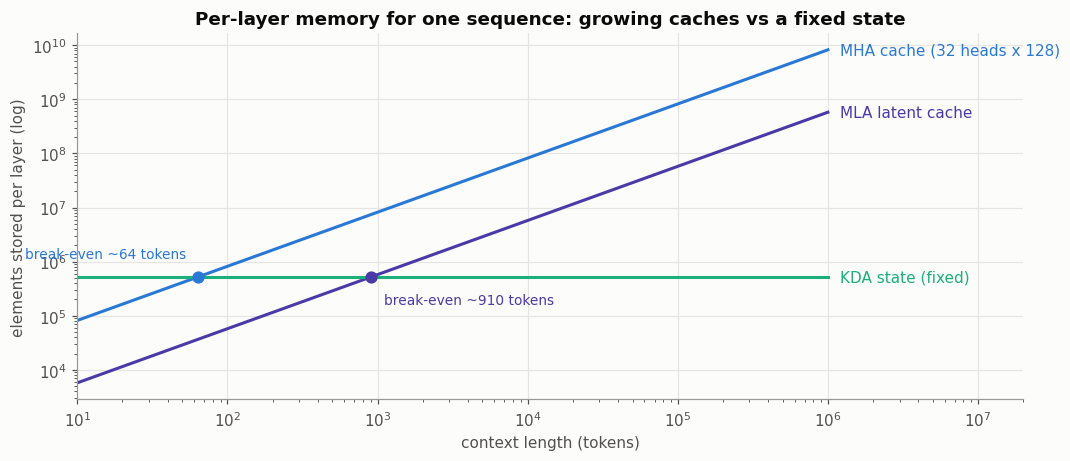

In [3]:
ctx = torch.logspace(1, 6, 200)
kda_state = 32 * 128 * 128                     # elements per layer, independent of context
mla_per_token = 512 + 64                       # Kimi Linear MLA: latent + decoupled key dims
mha_per_token = 2 * 32 * 128

fig, ax = plt.subplots(figsize=(10, 4.3))
ax.plot(ctx, mha_per_token * ctx, color=BLUE)
ax.plot(ctx, mla_per_token * ctx, color=VIOLET)
ax.plot(ctx, torch.full_like(ctx, kda_state), color=AQUA)
ax.text(1.2e6, mha_per_token * 1e6, "MHA cache (32 heads x 128)", color=BLUE, va="center")
ax.text(1.2e6, mla_per_token * 1e6, "MLA latent cache", color=VIOLET, va="center")
ax.text(1.2e6, kda_state, "KDA state (fixed)", color=AQUA, va="center")
for per_tok, col, offset, ha in [(mha_per_token, BLUE, (-8, 12), "right"), (mla_per_token, VIOLET, (8, -18), "left")]:
    cross = kda_state / per_tok
    ax.plot([cross], [kda_state], "o", color=col, markersize=7)
    ax.annotate(f"break-even ~{cross:,.0f} tokens", (cross, kda_state), textcoords="offset points",
                xytext=offset, ha=ha, color=col, fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(10, 2e7)
ax.set_xlabel("context length (tokens)"); ax.set_ylabel("elements stored per layer (log)")
ax.set_title("Per-layer memory for one sequence: growing caches vs a fixed state")
plt.tight_layout(); plt.show()

Beyond about a thousand tokens, a KDA layer stores **less** than even an MLA layer, and the gap grows linearly with context. The price is that a fixed-size memory cannot store everything. What it keeps, and how it overwrites, is exactly what the rest of the update rule controls.

# 2. The problem with additive memory, and the delta rule

Think of $S$ as an **associative memory** that maps keys to values. Reading with a stored key $k_i$ gives

$$S^\top k_i = \sum_j v_j (k_j^\top k_i) = \underbrace{v_i \|k_i\|^2}_{\text{signal}} + \underbrace{\sum_{j \ne i} v_j (k_j^\top k_i)}_{\text{crosstalk}}.$$

Purely additive writes ($S \mathrel{+}= k v^\top$) have two failure modes:
1. **Crosstalk.** Unless keys are orthogonal, every stored pair leaks into every retrieval, and it gets worse as more pairs are stored.
2. **No overwriting.** Writing the same key twice stores the *sum* of the two values. The memory cannot update a fact.

The **delta rule** fixes both. Before writing, read what the memory currently predicts for $k_t$ and write only the **correction** (the "delta"), scaled by a learned writing strength $\beta_t \in (0, 1)$:

$$S_t = S_{t-1} + \beta_t\, k_t \big(v_t - S_{t-1}^\top k_t\big)^\top = \big(I - \beta_t k_t k_t^\top\big) S_{t-1} + \beta_t k_t v_t^\top$$

With $\|k_t\| = 1$ and $\beta_t = 1$, the memory afterwards returns *exactly* $v_t$ for $k_t$ ($S_t^\top k_t = v_t$), and the old value is gone. This is why KDA (like DeltaNet) L2-normalizes its keys.

In [4]:
def additive_write(S, k, v, beta=1.0):
    # S: (d_k, d_v), k: (d_k,), v: (d_v,)
    return S + beta * torch.outer(k, v)

def delta_write(S, k, v, beta=1.0):
    # erase what S currently stores under k, then write v
    return S + beta * torch.outer(k, v - S.T @ k)

torch.manual_seed(1)
d_k, d_v = 64, 64
key = F.normalize(torch.randn(d_k), dim=0)
v_old, v_new = torch.randn(d_v), torch.randn(d_v)
cos = lambda a, b: F.cosine_similarity(a, b, dim=0).item()
for name, write in [("additive", additive_write), ("delta", delta_write)]:
    S = torch.zeros(d_k, d_v)
    S = write(S, key, v_old)          # store a fact
    S = write(S, key, v_new)          # update the same key with a new value
    r = S.T @ key
    print(f"{name:>8}: cos(read, v_new) = {cos(r, v_new):+.3f}   cos(read, v_old) = {cos(r, v_old):+.3f}")
print(f"(for reference, the two values themselves have cos(v_new, v_old) = {cos(v_new, v_old):+.3f})")

additive: cos(read, v_new) = +0.831   cos(read, v_old) = +0.773
   delta: cos(read, v_new) = +1.000   cos(read, v_old) = +0.290
(for reference, the two values themselves have cos(v_new, v_old) = +0.290)


Now crosstalk. We store $N$ random (unit-norm key, value) pairs in a $d_k = 64$ memory, in one pass, and then try to read every value back. The left panel shows the average retrieval error as $N$ grows. The right panel fixes $N = 48$ and shows the error for each pair by **how long ago** it was written.

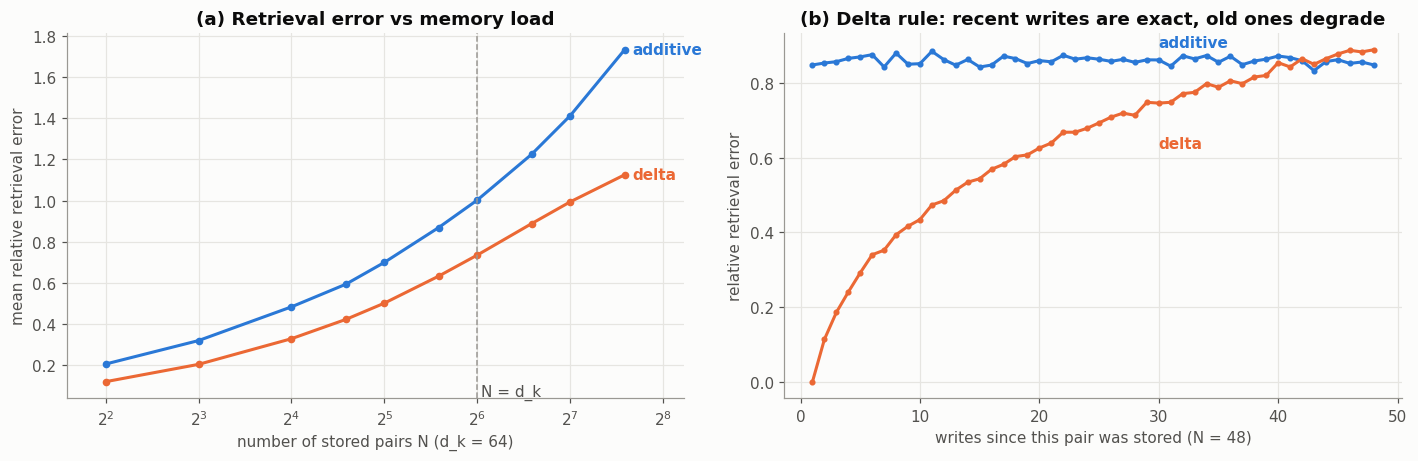

N=16: {'additive': 0.484, 'delta': 0.329}   N=128: {'additive': 1.412, 'delta': 0.994}


In [5]:
def store_and_recall(N, d_k=64, d_v=64, rule="delta", beta=1.0, trials=20, seed=0):
    """Write N random (key, value) pairs sequentially, then read each one back. Returns relative error per pair."""
    g = torch.Generator().manual_seed(seed)
    errs = []
    for _ in range(trials):
        K = F.normalize(torch.randn(N, d_k, generator=g), dim=-1)
        V = torch.randn(N, d_v, generator=g)
        S = torch.zeros(d_k, d_v)
        for i in range(N):
            S = delta_write(S, K[i], V[i], beta) if rule == "delta" else additive_write(S, K[i], V[i], beta)
        R = K @ S                                                        # read all keys: (N, d_v)
        errs.append((R - V).norm(dim=-1) / V.norm(dim=-1))
    return torch.stack(errs).mean(0)                                     # (N,), indexed by write order

Ns = [4, 8, 16, 24, 32, 48, 64, 96, 128, 192]
mean_err = {r: [store_and_recall(N, rule=r).mean().item() for N in Ns] for r in ["additive", "delta"]}
age_err = {r: store_and_recall(48, rule=r, trials=200) for r in ["additive", "delta"]}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3))
for r, col in [("additive", BLUE), ("delta", ORANGE)]:
    ax1.plot(Ns, mean_err[r], marker="o", markersize=4, color=col)
    ax1.text(Ns[-1] * 1.06, mean_err[r][-1], r, color=col, va="center", fontweight="bold")
    ages = torch.arange(48, 0, -1)                                       # pair i was written (48 - i) writes ago
    ax2.plot(ages, age_err[r], marker="o", markersize=3, color=col)
ax1.axvline(64, color=MUTED, linestyle="--", linewidth=1); ax1.text(66, 0.05, "N = d_k", color=INK_2)
ax1.set_xscale("log", base=2); ax1.set_xlim(3, 300)
ax1.set_xlabel("number of stored pairs N (d_k = 64)"); ax1.set_ylabel("mean relative retrieval error")
ax1.set_title("(a) Retrieval error vs memory load")
ax2.set_xlabel("writes since this pair was stored (N = 48)"); ax2.set_ylabel("relative retrieval error")
ax2.set_title("(b) Delta rule: recent writes are exact, old ones degrade")
ax2.text(30, age_err["additive"][20] + 0.04, "additive", color=BLUE, fontweight="bold")
ax2.text(30, age_err["delta"][18] - 0.12, "delta", color=ORANGE, fontweight="bold")
plt.tight_layout(); plt.show()
print("N=16:", {r: round(mean_err[r][2], 3) for r in mean_err}, "  N=128:", {r: round(mean_err[r][8], 3) for r in mean_err})

With random keys the delta rule has lower average error at every memory load, and the gap widens as the memory fills. The age profile (b) shows where the difference comes from. Each delta write makes the memory **exact** for the newest key and only partly disturbs older ones, so error rises smoothly with age, and the oldest pairs end up no better than additive memory. Additive memory is equally noisy for every pair, because every pair adds crosstalk to every other.

Even the delta rule cannot store more than $d_k$ independent associations, and old pairs still fade under interference. Real models also need to **choose** what to forget, which is the job of the gate (§4).

# 3. The delta rule is one step of online gradient descent

The DeltaNet paper (§2.2) gives a clean interpretation. At each step, treat $S$ as the weights of a linear regression from keys to values, and take one gradient step on the loss for the current pair:

$$\mathcal{L}_t(S) = \tfrac{1}{2}\big\|S^\top k_t - v_t\big\|^2, \qquad \nabla_S \mathcal{L}_t = k_t\big(S^\top k_t - v_t\big)^\top$$

$$S_t = S_{t-1} - \beta_t \nabla_S \mathcal{L}_t(S_{t-1}) = \big(I - \beta_t k_t k_t^\top\big)S_{t-1} + \beta_t k_t v_t^\top$$

In the paper's words, this is *"optimizing an online regression loss using a single step of SGD"*, with $\beta_t$ as a data-dependent learning rate. In the same view, Gated DeltaNet and KDA add **weight decay** ($\alpha$) on the memory before the gradient step. The Kimi Linear paper (Table 7) frames them as SGD on the *decayed* state $\tilde S_{t-1} = \mathrm{Diag}(\alpha_t) S_{t-1}$. Let's confirm with autograd:

In [6]:
torch.manual_seed(0)
S0 = torch.randn(16, 8, requires_grad=True)
k_t = F.normalize(torch.randn(16), dim=0)
v_t, beta_t = torch.randn(8), 0.7

loss = 0.5 * (S0.T @ k_t - v_t).pow(2).sum()
loss.backward()
sgd_step = S0.detach() - beta_t * S0.grad
delta_rule = (torch.eye(16) - beta_t * torch.outer(k_t, k_t)) @ S0.detach() + beta_t * torch.outer(k_t, v_t)
print(f"max |SGD step - delta rule| = {(sgd_step - delta_rule).abs().max():.1e}")

max |SGD step - delta rule| = 3.6e-07


# 4. Forgetting: from a scalar gate to channel-wise gates

A fixed-size memory must forget, and the delta rule only removes what the current key overlaps with. The family tree, written as state-update rules (Kimi Linear, Table 7):

| model | update rule | forgetting |
|---|---|---|
| Linear attention | $S_t = S_{t-1} + k_t v_t^\top$ | none |
| Mamba2 | $S_t = \alpha_t S_{t-1} + \beta_t k_t v_t^\top$ | scalar decay per head |
| GLA | $S_t = \mathrm{Diag}(\alpha_t) S_{t-1} + k_t v_t^\top$ | per-channel decay, no delta |
| DeltaNet | $S_t = (I - \beta_t k_t k_t^\top) S_{t-1} + \beta_t k_t v_t^\top$ | delta erase only |
| Gated DeltaNet | $S_t = (I - \beta_t k_t k_t^\top)\,\alpha_t S_{t-1} + \beta_t k_t v_t^\top$ | delta + **scalar** decay |
| **KDA** | $S_t = (I - \beta_t k_t k_t^\top)\,\mathrm{Diag}(\alpha_t) S_{t-1} + \beta_t k_t v_t^\top$ | delta + **per-channel** decay |

Row $c$ of $S$ belongs to key channel $c$, so $\mathrm{Diag}(\alpha_t)$ decays each key channel's memory at its own data-dependent rate. With $d_k = 128$, a single KDA head can keep some channels as long-term memory ($\alpha \approx 1$) and use others as fast scratch space ($\alpha \ll 1$). A Gated DeltaNet head has to pick one timescale for everything.

**Order matters.** With a scalar $\alpha$, $(I - \beta k k^\top)\alpha = \alpha (I - \beta k k^\top)$. With a diagonal $\mathrm{Diag}(\alpha)$ the two orders differ. KDA decays **first**, then applies the delta correction to the decayed state: Eq. 1 of the paper and the reference code both do this. (Table 6 of the paper writes the product in the other order, but the code is authoritative.)

**KDA as a constrained DPLR.** Expanding the update gives $S_t = \big(\mathrm{Diag}(\alpha_t) - \beta_t k_t (k_t \odot \alpha_t)^\top\big) S_{t-1} + \beta_t k_t v_t^\top$, a *diagonal-plus-low-rank* transition $D - a_t b_t^\top$ with $a_t = \beta_t k_t$ and $b_t = k_t \odot \alpha_t$. Tying both low-rank vectors to $k_t$ is what makes KDA's kernel cheaper. The paper reports *"nearly 2× the speed of DPLR for sequence lengths up to 64k"*.

### The gate parameterization

KDA computes the decay in **log space**, per head $h$ and key channel $c$ (Kimi Linear §4 and `fla/ops/kda/gate.py`):

$$g_{t} = -\exp(A_{\log,h}) \cdot \mathrm{softplus}\big(W_\alpha^\uparrow W_\alpha^\downarrow x_t + b_{dt}\big) \le 0, \qquad \alpha_t = \exp(g_t) \in (0, 1]$$

* $W_\alpha^\downarrow W_\alpha^\uparrow$ is a **low-rank** projection (rank = head dim), so the gate is cheap even though it outputs $H \cdot d_k$ values.
* $A_{\log}$ is one scalar per head, initialized as $\log U(1, 16)$. The bias $b_{dt}$ is one value per channel, initialized so that $\mathrm{softplus}(b_{dt}) = dt \sim \mathrm{LogUniform}(0.001, 0.1)$. This is the Mamba-style initialization.

At initialization (the projection output near 0), channel $c$ of head $h$ therefore has decay $\alpha = e^{-A_h\, dt_c}$ and memory **half-life** $\ln 2 / (A_h\, dt_c)$ tokens. The figure shows how wide a range of timescales this creates.

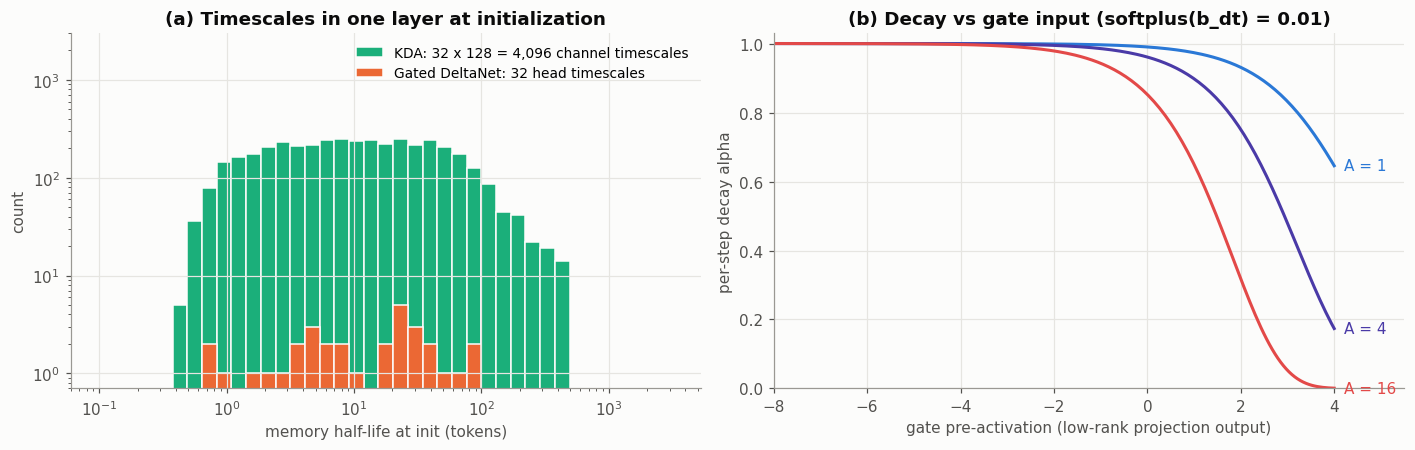

KDA half-lives at init span 0.46 to 476 tokens


In [7]:
torch.manual_seed(0)
H, d_k_kimi = 32, 128                                                   # Kimi Linear KDA layer
A = torch.empty(H).uniform_(1, 16)                                       # exp(A_log) ~ U(1, 16), one per head
dt = torch.exp(torch.rand(H * d_k_kimi) * (math.log(0.1) - math.log(0.001)) + math.log(0.001)).clamp(min=1e-4)
half_life_kda = math.log(2) / (A.repeat_interleave(d_k_kimi) * dt)      # one timescale per (head, channel)
dt_gdn = torch.exp(torch.rand(H) * (math.log(0.1) - math.log(0.001)) + math.log(0.001))
half_life_gdn = math.log(2) / (A * dt_gdn)                               # Gated DeltaNet: one timescale per head

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
bins = torch.logspace(-1, 3.5, 40)
ax1.hist(half_life_kda, bins=bins, color=AQUA, edgecolor="#fcfcfb", linewidth=1, label=f"KDA: {H} x {d_k_kimi} = {H * d_k_kimi:,} channel timescales")
ax1.hist(half_life_gdn, bins=bins, color=ORANGE, edgecolor="#fcfcfb", linewidth=1, label=f"Gated DeltaNet: {H} head timescales")
ax1.legend(loc="upper right", fontsize=9); ax1.set_ylim(0.7, 3000)
ax1.set_xscale("log"); ax1.set_yscale("log")
ax1.set_xlabel("memory half-life at init (tokens)"); ax1.set_ylabel("count")
ax1.set_title("(a) Timescales in one layer at initialization")

pre = torch.linspace(-8, 4, 200)
for A_h, col in [(1.0, BLUE), (4.0, VIOLET), (16.0, RED)]:
    alpha = torch.exp(-A_h * F.softplus(pre + math.log(math.expm1(0.01))))    # dt_bias chosen so softplus(b) = 0.01
    ax2.plot(pre, alpha, color=col)
    ax2.text(4.2, alpha[-1].item(), f"A = {A_h:g}", color=col, va="center")
ax2.set_xlim(-8, 5.5); ax2.set_ylim(0, 1.03)
ax2.set_xlabel("gate pre-activation (low-rank projection output)"); ax2.set_ylabel("per-step decay alpha")
ax2.set_title("(b) Decay vs gate input (softplus(b_dt) = 0.01)")
plt.tight_layout(); plt.show()
print(f"KDA half-lives at init span {half_life_kda.min():.2f} to {half_life_kda.max():,.0f} tokens")

A negative projection output pushes $\alpha \to 1$ (remember), and a positive one pushes it towards 0 (forget). Because the projection depends on the input, **each token decides, channel by channel, how much of the past to keep.** (§5 shows what these choices do to the effective attention pattern.)

# 5. A reference recurrent implementation

This is the ground truth everything else is checked against. It follows the paper's Eq. 1 and the reference `naive_recurrent_kda` in flash-linear-attention, and it handles the details that are easy to get wrong:
* gates are passed in **log space** ($g \le 0$, decay $= e^{g}$);
* the decay is applied **before** the delta correction;
* the output reads the state **after** this token's update ($o_t = S_t^\top q_t$);
* the query is scaled by $1/\sqrt{d_k}$.

Shapes follow the `(batch, heads, time, dim)` layout.

In [8]:
def kda_recurrent(q, k, v, g, beta, scale=None, initial_state=None):
    """
    Token-by-token Kimi Delta Attention.

    Args:
        q, k (tensor): (B, H, T, d_k), keys should be L2-normalized
        v (tensor): (B, H, T, d_v)
        g (tensor): (B, H, T, d_k) per-channel LOG decay (<= 0); alpha_t = exp(g_t)
        beta (tensor): (B, H, T) writing strength in (0, 1)
        scale (float): query scale, default 1/sqrt(d_k)
        initial_state (tensor): (B, H, d_k, d_v) or None

    Returns:
        o (B, H, T, d_v), final state S (B, H, d_k, d_v)
    """
    B, H, T, d_k = k.shape
    d_v = v.shape[-1]
    scale = d_k ** -0.5 if scale is None else scale
    S = q.new_zeros(B, H, d_k, d_v) if initial_state is None else initial_state.clone()
    o = []
    for t in range(T):
        q_t, k_t, v_t, b_t = q[:, :, t] * scale, k[:, :, t], v[:, :, t], beta[:, :, t]
        S = S * g[:, :, t].exp()[..., None]                              # 1) Diag(alpha_t) S: decay each key channel (row)
        v_pred = torch.einsum("bhk,bhkv->bhv", k_t, S)                   # 2) what the decayed memory predicts for k_t
        S = S + torch.einsum("bhk,bhv->bhkv", b_t[..., None] * k_t, v_t - v_pred)   # 3) write the correction (delta)
        o.append(torch.einsum("bhk,bhkv->bhv", q_t, S))                  # 4) read with the query, AFTER the update
    return torch.stack(o, dim=2), S

The special cases fall out by choosing the gate: $g = 0$ gives **DeltaNet**, and a $g$ that is constant across channels gives **Gated DeltaNet**. As an independent check, here is a separate scalar-gated implementation written directly from the Gated DeltaNet paper's convention (state stored as $d_v \times d_k$, $o_t = S_t q_t$, i.e. the transpose of KDA's), which must agree with KDA when all channels share one gate.

In [9]:
def gated_delta_rule_recurrent(q, k, v, g_scalar, beta):
    """Gated DeltaNet (Yang et al. 2024, Eq. 10): S_t = S_{t-1} (alpha_t (I - beta_t k_t k_t^T)) + beta_t v_t k_t^T with S in R^{d_v x d_k}."""
    B, H, T, d_k = k.shape
    S = q.new_zeros(B, H, v.shape[-1], d_k)
    eye = torch.eye(d_k, dtype=q.dtype)
    o = []
    for t in range(T):
        k_t, b_t = k[:, :, t], beta[:, :, t, None, None]
        transition = g_scalar[:, :, t, None, None].exp() * (eye - b_t * k_t[..., :, None] * k_t[..., None, :])
        S = S @ transition + b_t * v[:, :, t, :, None] * k_t[..., None, :]
        o.append(torch.einsum("bhvk,bhk->bhv", S, q[:, :, t] * d_k ** -0.5))
    return torch.stack(o, dim=2)

torch.manual_seed(0)
B, H, T, d_k, d_v = 2, 3, 24, 16, 8
q = F.normalize(torch.randn(B, H, T, d_k, dtype=torch.float64), dim=-1)
k = F.normalize(torch.randn(B, H, T, d_k, dtype=torch.float64), dim=-1)
v = torch.randn(B, H, T, d_v, dtype=torch.float64)
beta = torch.rand(B, H, T, dtype=torch.float64)
g_scalar = -torch.rand(B, H, T, dtype=torch.float64) * 0.2

o_gdn = gated_delta_rule_recurrent(q, k, v, g_scalar, beta)
o_kda, _ = kda_recurrent(q, k, v, g_scalar[..., None].expand(-1, -1, -1, d_k), beta)
print(f"KDA with channel-shared gates vs independent Gated DeltaNet: max |diff| = {(o_gdn - o_kda).abs().max():.1e}")

KDA with channel-shared gates vs independent Gated DeltaNet: max |diff| = 1.1e-16


### What each update rule does to the attention pattern

All of these layers are linear in $v$, so $o_t = \sum_j M_{tj} v_j$ for an **effective attention matrix** $M$ that depends on the queries, keys, gates and $\beta$s. We recover $M$ by running `kda_recurrent` with one-hot values ($v_j = e_j$). The four panels use the **same** random queries, keys and $\beta$, and differ only in the update rule.

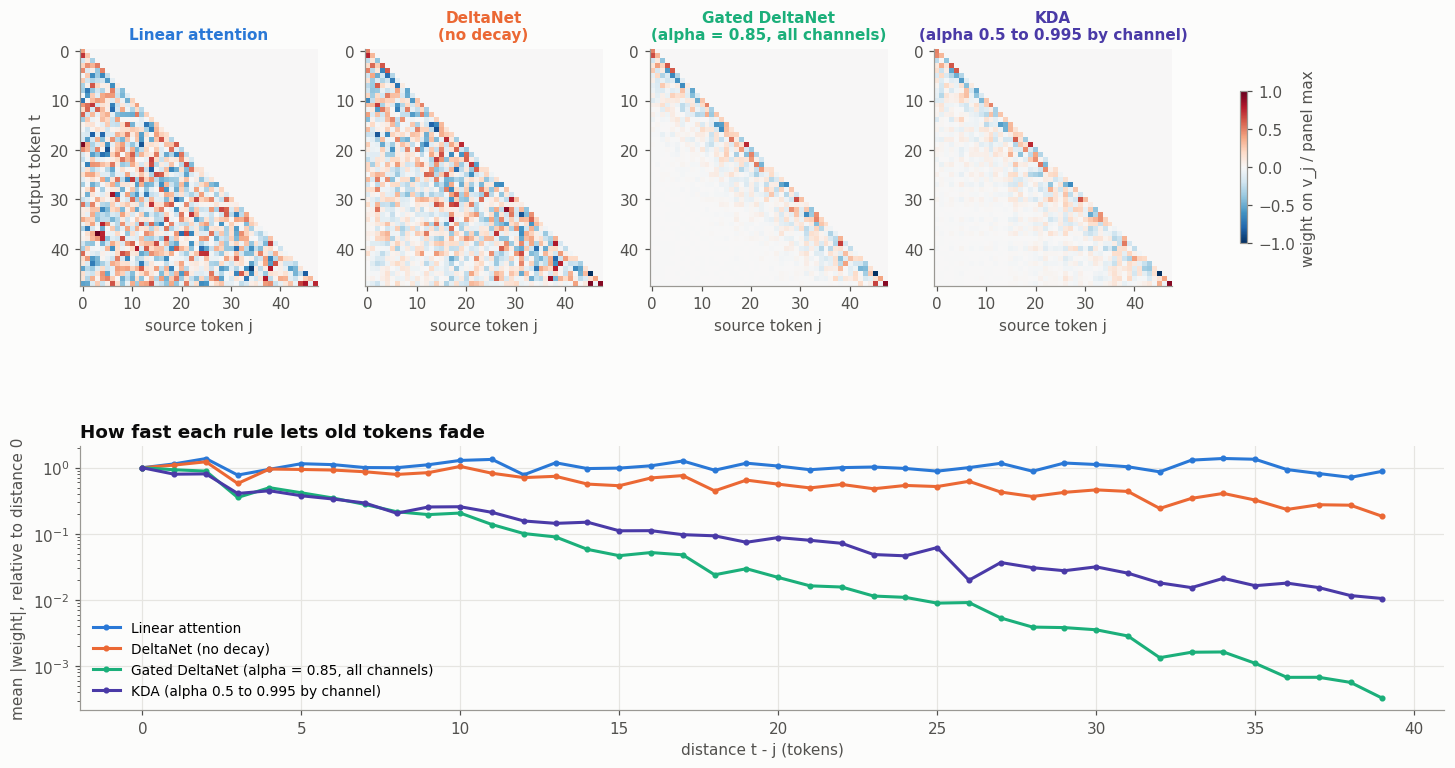

In [10]:
def effective_attention(q, k, g, beta, rule):
    """Recover the T x T mixing matrix M (o_t = sum_j M_tj v_j) by feeding one-hot values. Inputs: single head, (T, d)."""
    T = q.shape[0]
    eye_values = torch.eye(T, dtype=q.dtype)[None, None]                 # v_j = e_j
    if rule == "linear":
        return ((q @ k.T) * d_k ** -0.5).tril()
    o, _ = kda_recurrent(q[None, None], k[None, None], eye_values, g[None, None], beta[None, None])
    return o[0, 0]                                                       # row t = weights on each v_j

torch.manual_seed(3)
T_demo, d_k = 48, 16
qd = F.normalize(torch.randn(T_demo, d_k, dtype=torch.float64), dim=-1)
kd = F.normalize(torch.randn(T_demo, d_k, dtype=torch.float64), dim=-1)
bd = torch.full((T_demo,), 0.9, dtype=torch.float64)
g_none = torch.zeros(T_demo, d_k, dtype=torch.float64)
g_scalar_demo = torch.full((T_demo, d_k), math.log(0.85), dtype=torch.float64)            # one decay for the head
g_channel = torch.log(torch.linspace(0.5, 0.995, d_k, dtype=torch.float64)).expand(T_demo, d_k)  # fast...slow channels

panels = [("Linear attention", "linear", g_none, BLUE), ("DeltaNet\n(no decay)", "kda", g_none, ORANGE),
          ("Gated DeltaNet\n(alpha = 0.85, all channels)", "kda", g_scalar_demo, AQUA),
          ("KDA\n(alpha 0.5 to 0.995 by channel)", "kda", g_channel, VIOLET)]
fig = plt.figure(figsize=(16, 8.2))
grid = fig.add_gridspec(2, 4, height_ratios=[1.15, 1], hspace=0.45)
profile_ax = fig.add_subplot(grid[1, :])
for col, (title, rule, g_, color) in enumerate(panels):
    M = effective_attention(qd, kd, g_, bd, rule)
    M_norm = M / M.abs().max()                                         # each panel on its own scale
    ax = fig.add_subplot(grid[0, col])
    im = ax.imshow(M_norm, cmap="RdBu_r", norm=TwoSlopeNorm(0, -1, 1))
    ax.set_title(title, fontsize=10, color=color); ax.set_xlabel("source token j"); ax.grid(False)
    if col == 0:
        ax.set_ylabel("output token t")
    # average |weight| as a function of distance t - j, normalized so distance 0 = 1
    dist = torch.arange(T_demo)[:, None] - torch.arange(T_demo)[None, :]
    prof = torch.stack([M[dist == d_].abs().mean() for d_ in range(T_demo - 8)])
    profile_ax.plot(range(T_demo - 8), prof / prof[0], color=color, marker="o", markersize=3, label=title.replace("\n", " "))
fig.colorbar(im, ax=fig.axes[1:], shrink=0.5, label="weight on v_j / panel max", location="right")
profile_ax.set_yscale("log"); profile_ax.legend(loc="lower left", fontsize=9)
profile_ax.set_xlabel("distance t - j (tokens)"); profile_ax.set_ylabel("mean |weight|, relative to distance 0")
profile_ax.set_title("How fast each rule lets old tokens fade", loc="left")
plt.show()

* **Linear attention** gives the same expected weight to a token 1 step back and 40 steps back. It has no notion of recency or overwriting.
* **DeltaNet** fades old tokens without any decay gate: every write partly erases what overlaps with the new key. The weights can also be **negative**, because the erase step subtracts old values. Softmax attention can never do this.
* **Gated DeltaNet** adds one exponential fade at a single rate (the straight line on the log plot).
* **KDA** mixes timescales within a single head. The fast channels make the weight drop sharply over the first few tokens, and the slow channels keep a long tail that fades more slowly than Gated DeltaNet's single rate.

# 6. The chunkwise-parallel algorithm

The recurrence is exact but sequential: $T$ dependent rank-1 updates, none of which uses a large matrix multiply. Training needs the GPU's tensor cores, so KDA (like DeltaNet, Gated DeltaNet and GLA) uses a **chunkwise** algorithm. The sequence is split into chunks of $C$ tokens (64 in Kimi Linear). Everything **inside** a chunk is done with dense $C \times C$ matmuls, and only a $d_k \times d_v$ state is passed **between** chunks.

### Derivation

Take one chunk with incoming state $S_0$ and tokens $r = 1..C$. Let $g_r$ be the **cumulative** log-decay inside the chunk ($g_r = \sum_{i \le r} \log \alpha_i$, so $\gamma_r = e^{g_r}$ is the total decay since the chunk started), and $\Gamma_r = \mathrm{Diag}(\gamma_r)$.

**Step 1: remove the decay.** Define a "decay-normalized" state $\tilde S_r = \Gamma_r^{-1} S_r$. Substituting into $S_r = (I - \beta_r k_r k_r^\top)\mathrm{Diag}(\alpha_r)S_{r-1} + \beta_r k_r v_r^\top$ and using $\mathrm{Diag}(\alpha_r)\Gamma_{r-1} = \Gamma_r$ gives a **pure delta rule** with modified keys:

$$\tilde S_r = \tilde S_{r-1} + \hat k_r u_r^\top, \qquad u_r = \beta_r\big(v_r - \tilde S_{r-1}^\top \bar k_r\big), \qquad \hat k_r = k_r / \gamma_r, \;\; \bar k_r = k_r \odot \gamma_r$$

**Step 2: unroll.** Since $\tilde S_{r-1} = S_0 + \sum_{i<r} \hat k_i u_i^\top$:

$$u_r = \beta_r\Big(v_r - S_0^\top \bar k_r - \sum_{i<r} u_i\, (\hat k_i^\top \bar k_r)\Big)$$

**Step 3: solve the triangular system (UT transform).** Stack the rows. With the strictly lower-triangular matrix $A_{ri} = \beta_r\, \bar k_r^\top \hat k_i = \beta_r \sum_c k_{r,c}\, k_{i,c}\, e^{g_{r,c} - g_{i,c}}$ for $i < r$:

$$(I + A)\,U = \mathrm{Diag}(\beta)(V - \bar K S_0) \;\;\Rightarrow\;\; U = \underbrace{T\,\mathrm{Diag}(\beta)V}_{U'} - \underbrace{T\,\mathrm{Diag}(\beta)\bar K}_{W} S_0, \qquad T = (I + A)^{-1}$$

$T$ is the inverse of a unit lower-triangular matrix, computed row by row with forward substitution. This is the **WY representation**: all of the chunk's sequential delta-rule dependencies are folded into two matrices $W, U'$ that do **not** depend on $S_0$, so they can be computed for all chunks in parallel.

**Step 4: outputs and the next state.** Undoing the normalization ($S_r = \Gamma_r \tilde S_r$):

$$O = \underbrace{(Q \odot \gamma) S_0}_{\text{from previous chunks}} + \underbrace{\big(A^{qk} \odot M_{\le}\big)\,U}_{\text{inside this chunk}}, \qquad A^{qk}_{ri} = \sum_c q_{r,c}\,k_{i,c}\,e^{g_{r,c} - g_{i,c}}$$

$$S_C = \mathrm{Diag}(\gamma_C) S_0 + \big(K \odot e^{\,g_C - g}\big)^\top U$$

These match Eq. 6–9 of the Kimi Linear paper. The paper draws Eq. 9 as block matrices, which is a good way to see the shapes: the output of a chunk is the previous state read through decayed queries (inter-chunk) plus a lower-triangular, decay-weighted query–key matrix applied to the chunk's "pseudo-values" $U - WS$ (intra-chunk).

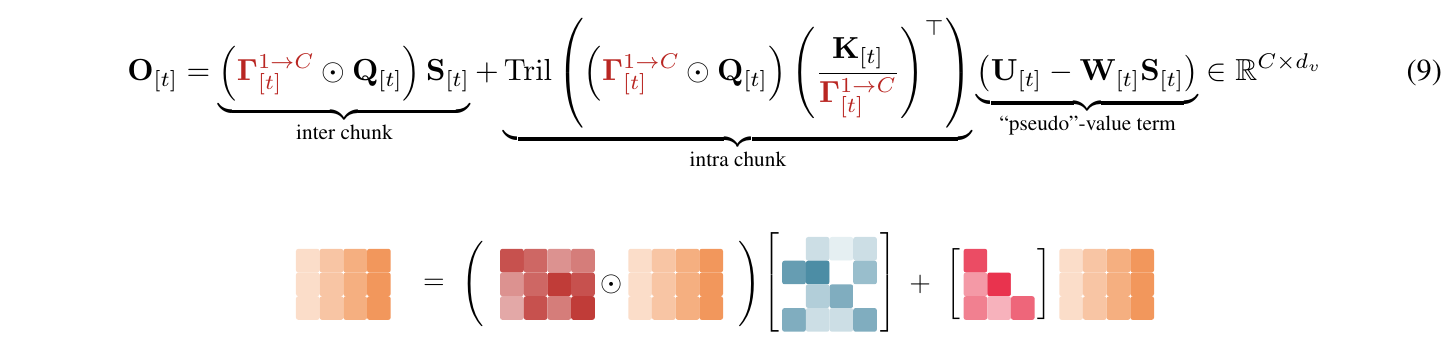

*Kimi Linear, Eq. 9 and its block illustration. The paper's $\Gamma^{1\to C}$ is our $\gamma = e^{g}$, $\mathbf{U}_{[t]} - \mathbf{W}_{[t]}\mathbf{S}_{[t]}$ is our `U_prime - W @ S`, and the division by $\Gamma$ inside the Tril is exactly the term we compute as $e^{g_r - g_i}$ to stay numerically stable. Source: [arXiv:2510.26692](https://arxiv.org/abs/2510.26692), CC BY-NC-ND 4.0.* Note the **diagonal convention**: $A$ excludes the diagonal ($i < r$), while $A^{qk}$ includes it ($i \le r$), because the output reads the state *after* the current token's write.

**Numerics.** The paper warns that *"the reciprocal of the cumulative decay term $1/\Gamma$ ... can introduce numerical instability."* We therefore never form $\gamma$ and $1/\gamma$ separately. Every product $\gamma_r / \gamma_i$ is computed as $e^{g_r - g_i}$ with $i \le r$, which is always in $(0, 1]$.

First, the UT transform on its own:

In [11]:
def ut_transform(A: torch.Tensor) -> torch.Tensor:
    """
    Inverse of (I + A) for strictly lower-triangular A (..., C, C), by forward substitution, one row at a time:
        T[i, :] = e_i - sum_{m < i} A[i, m] T[m, :]
    Written without in-place writes so autograd can differentiate through it.
    """
    C = A.shape[-1]
    eye = torch.eye(C, dtype=A.dtype, device=A.device)
    rows = [eye[0].expand(A.shape[:-2] + (C,))]                          # row 0 of T is e_0
    for i in range(1, C):
        prev = torch.stack(rows, dim=-2)                                 # rows 0..i-1 of T: (..., i, C)
        rows.append(eye[i] - (A[..., i, :i, None] * prev).sum(-2))
    return torch.stack(rows, dim=-2)

A_test = torch.randn(3, 16, 16, dtype=torch.float64).tril(-1) * 0.3
T_fs = ut_transform(A_test)
T_inv = torch.linalg.inv(torch.eye(16, dtype=torch.float64) + A_test)
T_tri = torch.linalg.solve_triangular(torch.eye(16, dtype=torch.float64) + A_test, torch.eye(16, dtype=torch.float64).expand(3, 16, 16), upper=False, unitriangular=True)
print(f"forward substitution vs torch.linalg.inv:          {(T_fs - T_inv).abs().max():.1e}")
print(f"forward substitution vs triangular solve (fast path): {(T_fs - T_tri).abs().max():.1e}")

forward substitution vs torch.linalg.inv:          8.9e-16
forward substitution vs triangular solve (fast path): 8.9e-16


In [12]:
def kda_chunkwise(q, k, v, g, beta, scale=None, initial_state=None, chunk_size=64, solver="triangular"):
    """
    Chunkwise-parallel Kimi Delta Attention. Same inputs/outputs as kda_recurrent.
    solver: "forward_substitution" (the explicit UT transform above) or "triangular" (same math, faster).
    """
    B, H, T, d_k = k.shape
    d_v = v.shape[-1]
    C = chunk_size
    scale = d_k ** -0.5 if scale is None else scale
    # Pad the sequence to a multiple of C. Padded tokens have k = v = 0, beta = 0 and g = 0 (no decay),
    # so they leave the state untouched; their outputs are dropped at the end.
    pad = (-T) % C
    if pad:
        q, k, v, g = (F.pad(x, (0, 0, 0, pad)) for x in (q, k, v, g))
        beta = F.pad(beta, (0, pad))
    n = (T + pad) // C
    # (B, H, n*C, d) -> (B, H, n, C, d)
    q, k, v, g = (x.reshape(B, H, n, C, -1) for x in (q, k, v, g))
    beta = beta.reshape(B, H, n, C)
    q = q * scale

    g = g.cumsum(dim=-2)                                                 # cumulative log-decay WITHIN each chunk
    # pairwise decay exp(g_r - g_i) for i <= r (always in (0, 1]); zero above the diagonal
    incl = torch.ones(C, C, dtype=torch.bool, device=q.device).tril()
    diff = g[..., :, None, :] - g[..., None, :, :]                       # (B, H, n, C_r, C_i, d_k)
    decay = diff.masked_fill(~incl[..., None], float("-inf")).exp()

    # A_kk[r, i] = beta_r * sum_c k_rc k_ic exp(g_rc - g_ic), strictly lower triangular
    A_kk = torch.einsum("bhnrc,bhnic,bhnric->bhnri", k, k, decay) * beta[..., None]
    A_kk = A_kk.tril(-1)
    if solver == "forward_substitution":
        T_mat = ut_transform(A_kk)
    else:
        eye = torch.eye(C, dtype=q.dtype, device=q.device)
        T_mat = torch.linalg.solve_triangular(eye + A_kk, eye.expand_as(A_kk), upper=False, unitriangular=True)

    W = T_mat @ (beta[..., None] * (k * g.exp()))                        # (B, H, n, C, d_k)   T Diag(beta) K_bar
    U_prime = T_mat @ (beta[..., None] * v)                              # (B, H, n, C, d_v)   T Diag(beta) V
    A_qk = torch.einsum("bhnrc,bhnic,bhnric->bhnri", q, k, decay)        # inclusive lower triangular (diag kept)

    S = q.new_zeros(B, H, d_k, d_v) if initial_state is None else initial_state
    outputs = []
    for j in range(n):                                                   # only the d_k x d_v state is sequential
        U = U_prime[:, :, j] - W[:, :, j] @ S                            # the chunk's delta-rule "corrections"
        outputs.append((q[:, :, j] * g[:, :, j].exp()) @ S + A_qk[:, :, j] @ U)
        g_last = g[:, :, j, -1]                                          # total log-decay of the chunk: (B, H, d_k)
        k_to_end = k[:, :, j] * (g_last[..., None, :] - g[:, :, j]).exp()
        S = S * g_last.exp()[..., None] + k_to_end.transpose(-1, -2) @ U
    o = torch.stack(outputs, dim=2).reshape(B, H, n * C, d_v)[:, :, :T]
    return o, S

**Verification against the recurrence.** The chunkwise algorithm is only a re-arrangement of the same arithmetic, so in float64 it must match `kda_recurrent` to machine precision for any chunk size, for sequence lengths that are not a multiple of the chunk size, with a non-zero initial state, and for **gradients** as well as outputs.

In [13]:
torch.manual_seed(0)
B, H, T, d_k, d_v = 2, 3, 50, 16, 8
f64 = dict(dtype=torch.float64)
q = F.normalize(torch.randn(B, H, T, d_k, **f64), dim=-1).requires_grad_()
k = F.normalize(torch.randn(B, H, T, d_k, **f64), dim=-1).requires_grad_()
v = torch.randn(B, H, T, d_v, **f64).requires_grad_()
g = (-F.softplus(torch.randn(B, H, T, d_k, **f64)) * 0.5).requires_grad_()   # log-decays <= 0
beta = torch.rand(B, H, T, **f64).requires_grad_()
S_init = torch.randn(B, H, d_k, d_v, **f64)
w_out = torch.randn(B, H, T, d_v, **f64)                                     # random cotangent for the backward check

def grads(fn):
    for x in (q, k, v, g, beta):
        x.grad = None
    o, S = fn()
    ((o * w_out).sum() + S.sum()).backward()
    return o.detach(), S.detach(), [x.grad.clone() for x in (q, k, v, g, beta)]

o_ref, S_ref, g_ref = grads(lambda: kda_recurrent(q, k, v, g, beta, initial_state=S_init))
for C in [8, 16, 32, 64]:
    for solver in ["forward_substitution", "triangular"]:
        o_c, S_c, g_c = grads(lambda: kda_chunkwise(q, k, v, g, beta, initial_state=S_init, chunk_size=C, solver=solver))
        grad_err = max((a - b).abs().max().item() for a, b in zip(g_ref, g_c))
        print(f"C={C:>2} {solver:>20}: output {(o_ref - o_c).abs().max():.1e}  state {(S_ref - S_c).abs().max():.1e}  grads {grad_err:.1e}")

C= 8 forward_substitution: output 1.1e-16  state 2.2e-16  grads 1.3e-15
C= 8           triangular: output 1.1e-16  state 2.2e-16  grads 1.3e-15
C=16 forward_substitution: output 1.1e-16  state 2.2e-16  grads 1.3e-15
C=16           triangular: output 1.1e-16  state 2.2e-16  grads 1.3e-15
C=32 forward_substitution: output 1.9e-16  state 3.3e-16  grads 2.7e-15
C=32           triangular: output 1.9e-16  state 3.3e-16  grads 2.7e-15
C=64 forward_substitution: output 1.9e-16  state 1.7e-15  grads 5.8e-15
C=64           triangular: output 1.9e-16  state 1.7e-15  grads 5.8e-15


Here is what the matrices inside one chunk look like for a single head: the strictly lower-triangular interaction $A$ between keys, its UT-transform inverse $T = (I + A)^{-1}$, and the inclusive query-key matrix $A^{qk}$. The decay makes all of them fade away from the diagonal.

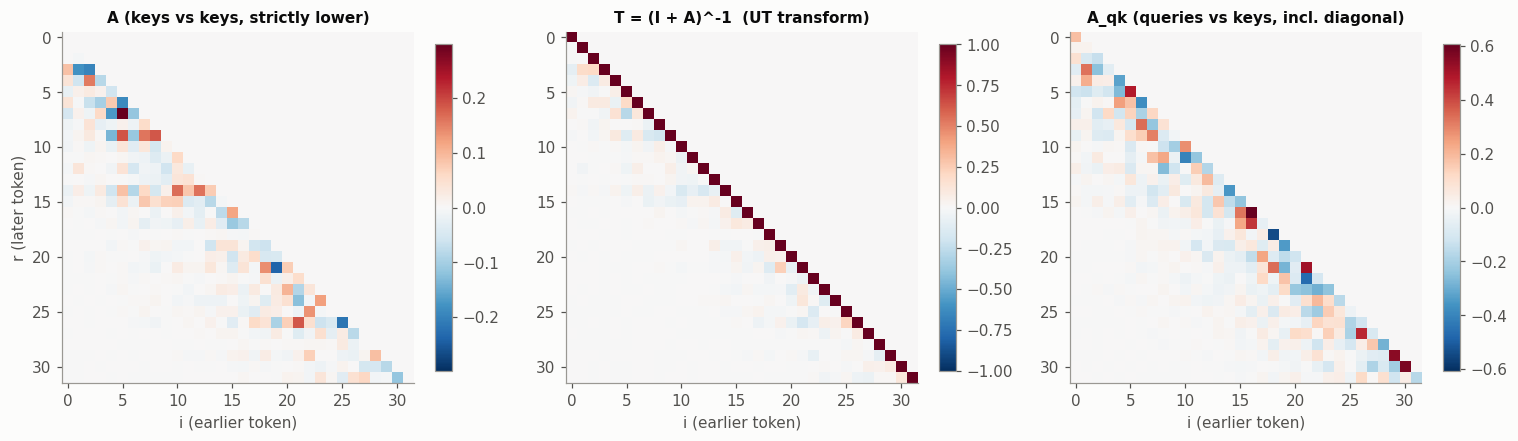

In [14]:
torch.manual_seed(1)
C, d_k = 32, 16
kc = F.normalize(torch.randn(C, d_k, dtype=torch.float64), dim=-1)
qc = F.normalize(torch.randn(C, d_k, dtype=torch.float64), dim=-1)
gc = (-F.softplus(torch.randn(C, d_k, dtype=torch.float64)) * 0.3).cumsum(0)
bc = torch.rand(C, dtype=torch.float64)
dec = (gc[:, None, :] - gc[None, :, :]).masked_fill(~torch.ones(C, C, dtype=torch.bool).tril()[..., None], float("-inf")).exp()
A_kk = (torch.einsum("rc,ic,ric->ri", kc, kc, dec) * bc[:, None]).tril(-1)
T_mat = ut_transform(A_kk)
A_qk = torch.einsum("rc,ic,ric->ri", qc, kc, dec)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
for ax, (title, M) in zip(axes, [("A (keys vs keys, strictly lower)", A_kk), ("T = (I + A)^-1  (UT transform)", T_mat),
                                  ("A_qk (queries vs keys, incl. diagonal)", A_qk)]):
    lim = M.abs().max().item()
    im = ax.imshow(M, cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim, lim))
    ax.set_title(title, fontsize=10); ax.grid(False); ax.set_xlabel("i (earlier token)")
    fig.colorbar(im, ax=ax, shrink=0.75)
axes[0].set_ylabel("r (later token)")
plt.tight_layout(); plt.show()

**The numerical pitfall, demonstrated.** Write the same intra-chunk matrix the "obvious" way, $(\bar K)(\hat K)^\top = (K \odot \gamma)(K / \gamma)^\top$, with strongly decaying channels in float32. The cumulative decay over a 64-token chunk underflows and its reciprocal overflows, giving `inf * 0 = nan`. The pairwise form never leaves $(0, 1]$:

In [15]:
torch.manual_seed(0)
C, d_k = 64, 16
k32 = F.normalize(torch.randn(C, d_k), dim=-1)
g_strong = torch.full((C, d_k), -2.0)                    # alpha = e^-2 ~ 0.135 per step in every channel
g_cum = g_strong.cumsum(0)                               # reaches -128 by the end of the chunk
gamma = g_cum.exp()
A_naive = ((k32 * gamma) @ (k32 / gamma).T).tril(-1)     # gamma_r / gamma_i formed from two separate factors
A_pairwise = torch.einsum("rc,ic,ric->ri", k32, k32,
                          (g_cum[:, None] - g_cum[None]).clamp(max=0).exp()).tril(-1)
print(f"smallest gamma = {gamma.min():.1e}, largest 1/gamma = {(1 / gamma).max():.1e}")
print(f"naive    : {torch.isnan(A_naive).sum().item()} NaNs, {torch.isinf(A_naive).sum().item()} infs out of {C * (C - 1) // 2} entries")
print(f"pairwise : {torch.isnan(A_pairwise).sum().item()} NaNs, all finite = {torch.isfinite(A_pairwise).all().item()}")

smallest gamma = 0.0e+00, largest 1/gamma = inf
naive    : 190 NaNs, 0 infs out of 2016 entries
pairwise : 0 NaNs, all finite = True


Finally, speed. On this CPU (forward pass only, 4 heads, $d_k = d_v = 32$) we compare the token-by-token recurrence with the chunkwise algorithm. The chunkwise version does *more* arithmetic, about $O(T C d)$ extra for the intra-chunk matrices, but it replaces $T$ tiny sequential steps with $T/C$ batched matmuls. On a GPU the difference is much larger.

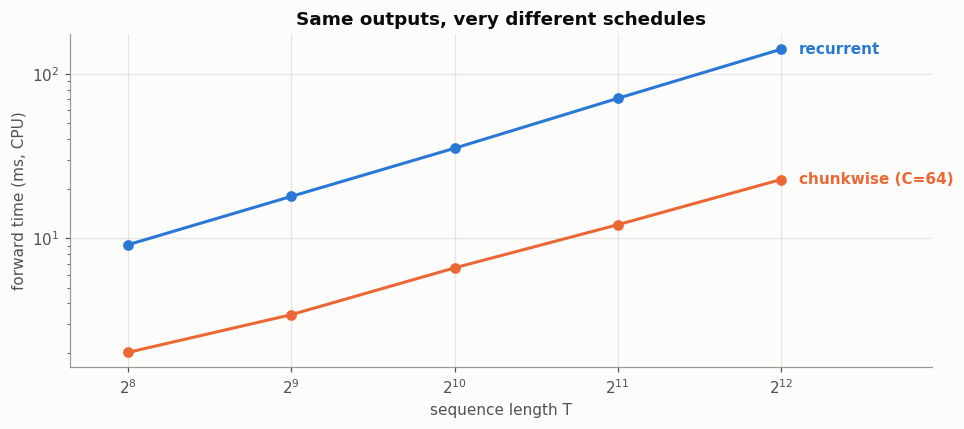

speed-up: {256: 4.5, 512: 5.3, 1024: 5.4, 2048: 5.9, 4096: 6.2}


In [16]:
torch.manual_seed(0)
lengths = [256, 512, 1024, 2048, 4096]
t_rec, t_chunk = [], []
for T_len in lengths:
    args = (F.normalize(torch.randn(1, 4, T_len, 32), dim=-1), F.normalize(torch.randn(1, 4, T_len, 32), dim=-1),
            torch.randn(1, 4, T_len, 32), -torch.rand(1, 4, T_len, 32) * 0.1, torch.rand(1, 4, T_len))
    with torch.no_grad():
        t0 = time.perf_counter(); kda_recurrent(*args); t_rec.append(time.perf_counter() - t0)
        kda_chunkwise(*args, chunk_size=64)                                  # warm-up
        t0 = time.perf_counter(); kda_chunkwise(*args, chunk_size=64); t_chunk.append(time.perf_counter() - t0)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(lengths, [t * 1e3 for t in t_rec], marker="o", color=BLUE)
ax.plot(lengths, [t * 1e3 for t in t_chunk], marker="o", color=ORANGE)
ax.text(lengths[-1] * 1.08, t_rec[-1] * 1e3, "recurrent", color=BLUE, va="center", fontweight="bold")
ax.text(lengths[-1] * 1.08, t_chunk[-1] * 1e3, "chunkwise (C=64)", color=ORANGE, va="center", fontweight="bold")
ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xlim(200, 4096 * 1.9)
ax.set_xlabel("sequence length T"); ax.set_ylabel("forward time (ms, CPU)")
ax.set_title("Same outputs, very different schedules")
plt.tight_layout(); plt.show()
print("speed-up:", {L: round(r / c, 1) for L, r, c in zip(lengths, t_rec, t_chunk)})

On a GPU, the paper's Triton kernel shows the payoff of the KDA-specific structure. Because both low-rank vectors of the DPLR transition are tied to $k$ (§4 of this notebook; §6.2 of the paper), KDA needs fewer secondary-chunking steps than a general DPLR recurrence and runs about twice as fast:

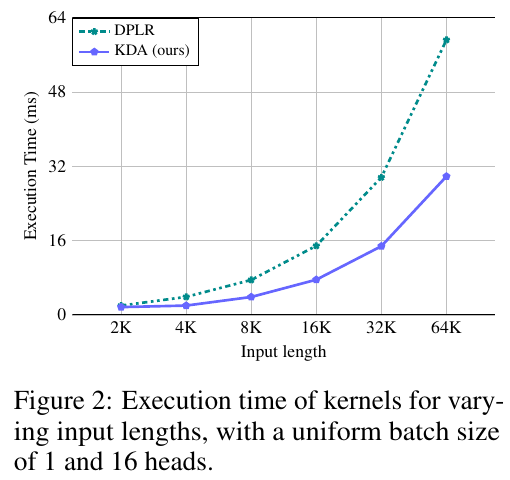

*Kimi Linear, Figure 2. Source: [arXiv:2510.26692](https://arxiv.org/abs/2510.26692), CC BY-NC-ND 4.0.*

# 7. The full KDA layer

The recurrence is the core. A KDA *layer* wraps it with the parameterization from Kimi Linear §4, which matches `fla/layers/kda.py` and `modeling_kimi.py`:

$$q_t, k_t = \mathrm{L2Norm}\big(\mathrm{Swish}(\mathrm{ShortConv}(W_{q/k} x_t))\big), \qquad v_t = \mathrm{Swish}(\mathrm{ShortConv}(W_v x_t))$$
$$\alpha_t = f\big(W_\alpha^\uparrow W_\alpha^\downarrow x_t\big) \in [0,1]^{d_k}, \qquad \beta_t = \mathrm{Sigmoid}(W_\beta x_t) \in [0, 1]$$
$$o_t = W_o\Big(\mathrm{Sigmoid}\big(W_g^\uparrow W_g^\downarrow x_t\big) \odot \mathrm{RMSNorm}\big(\mathrm{KDA}(q_t, k_t, v_t, \alpha_t, \beta_t)\big)\Big)$$

| component | what it does | Kimi Linear 48B-A3B |
|---|---|---|
| `q_proj, k_proj, v_proj` | per-head projections (no bias) | 32 heads × 128 |
| `ShortConv` | causal depthwise conv + SiLU on q, k, v: cheap local token mixing | kernel size 4 |
| L2 norm on q, k | unit-norm keys make the delta rule well-posed (eigenvalues of $I - \beta k k^\top$ stay in $[0, 1]$) | in kernel |
| `f_proj` (low rank) + `A_log` + `dt_bias` | per-channel log-decay $g = -e^{A_{\log}} \,\mathrm{softplus}(\cdot + b_{dt})$ | rank = head dim |
| `b_proj` | $\beta$ (writing strength), one per head | sigmoid |
| `g_proj` (low rank) | output gate | sigmoid |
| `o_norm` | head-wise RMSNorm, then multiply by the gate | per head |
| `o_proj` | back to the residual stream | 4096 → 2304 |

The paper's architecture figure shows the same layer (bottom right) inside the 3:1 hybrid (left). Reading the KDA block left to right: q and k go through Linear → Conv → SiLU → L2 norm, v through Linear → Conv → SiLU, the low-rank (hourglass-shaped) projection with a sigmoid-family gate produces $\alpha$, a single projection gives $\beta$, and a second low-rank projection gives the output gate that multiplies the normalized output before the final Linear.

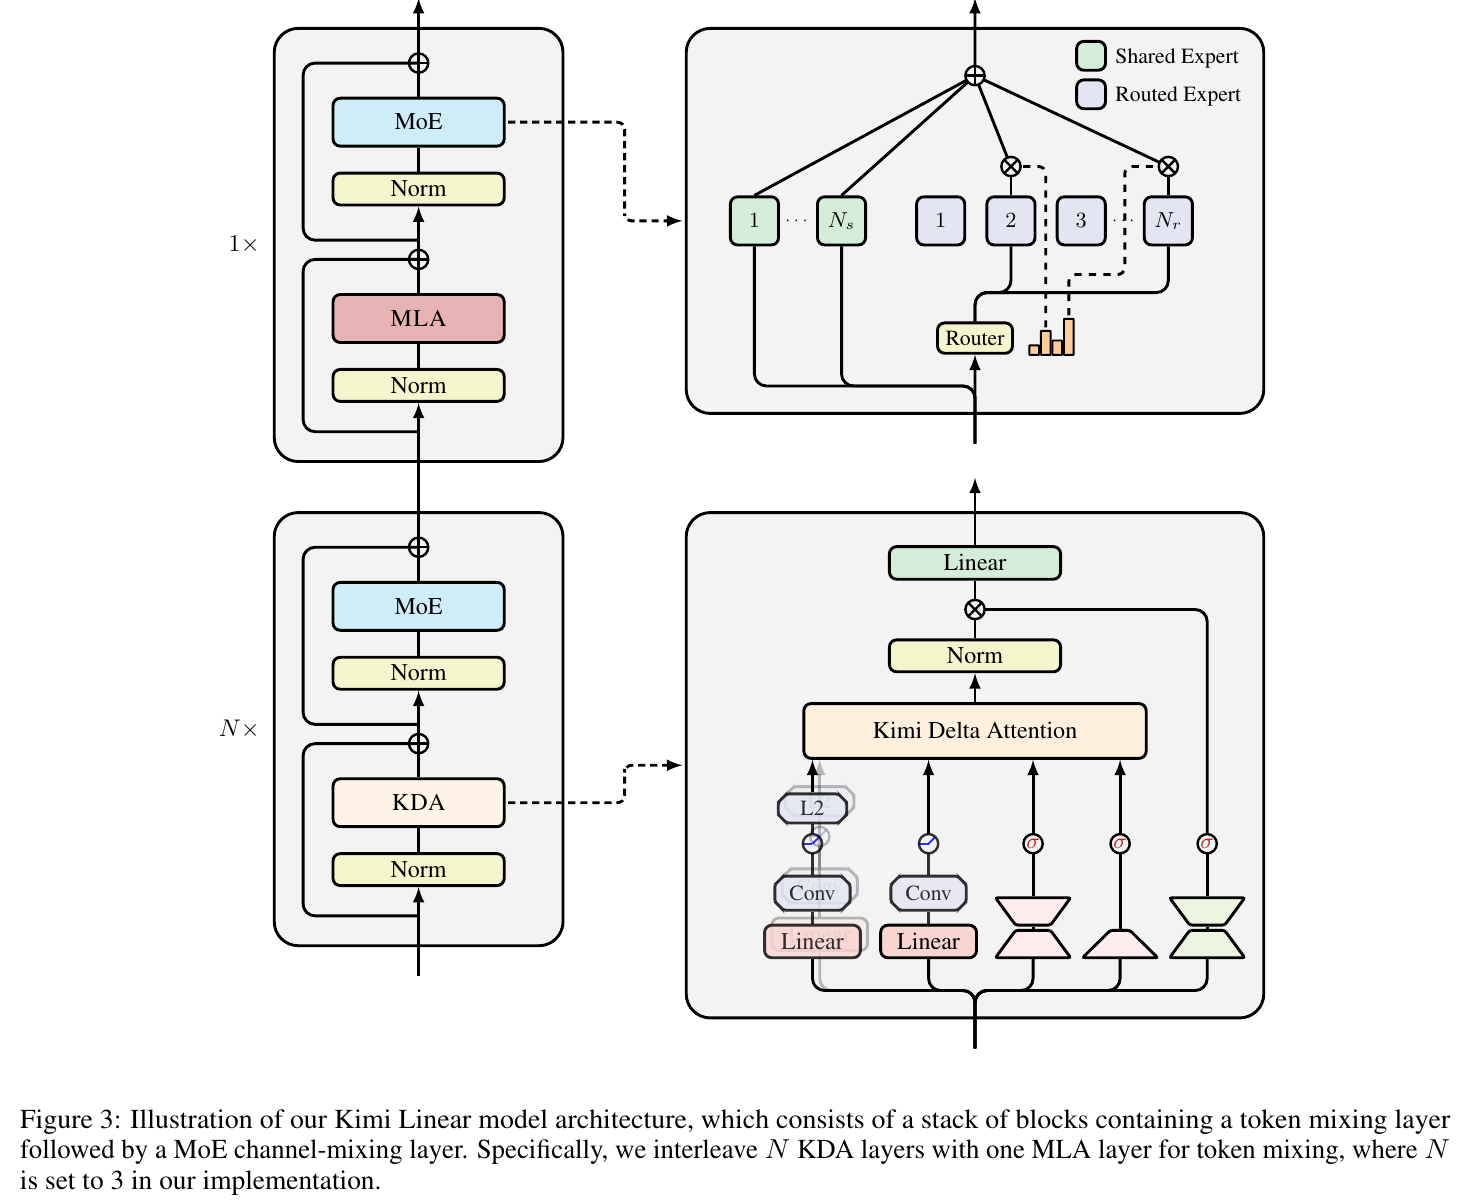

*Kimi Linear, Figure 3. Source: [arXiv:2510.26692](https://arxiv.org/abs/2510.26692), CC BY-NC-ND 4.0.*

Compare it with its direct predecessor, the Gated DeltaNet block. The skeleton is identical. The differences are exactly KDA's changes: a per-channel low-rank $\alpha$ instead of one scalar per head, and a low-rank output gate that uses a **sigmoid** instead of a full-rank SiLU gate (the Kimi ablation found a swish/SiLU output gate clearly worse: 5.81 vs 5.65 validation perplexity).

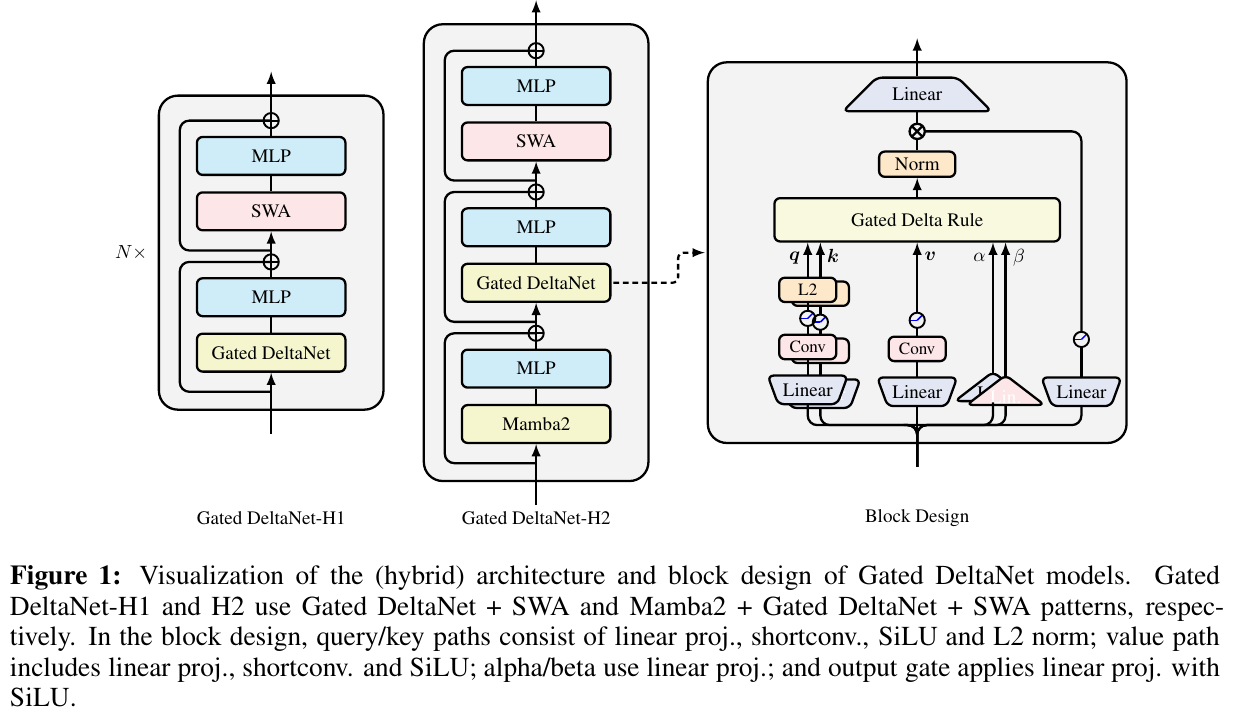

*Gated DeltaNet, Figure 1. Source: [Yang, Kautz & Hatamizadeh, arXiv:2412.06464](https://arxiv.org/abs/2412.06464), CC BY 4.0.*

The paper's ablation (Table 1) supports the extra pieces: removing the output gate or the convolution makes perplexity worse, and a *swish* output gate is worse than *sigmoid*. The layer also exposes a `gate` switch, so that the same code can become DeltaNet, Gated DeltaNet or plain linear attention for the experiment in §9.

In [17]:
class ShortConv(nn.Module):
    def __init__(self, dim: int, kernel_size: int = 4):
        """Causal depthwise 1D convolution followed by SiLU. Keeps the last (kernel_size - 1) inputs as decoding state."""
        super().__init__()
        self.kernel_size = kernel_size
        self.weight = nn.Parameter(torch.randn(kernel_size, dim) / math.sqrt(kernel_size))

    def forward(self, x, conv_state=None):
        # x: (B, T, dim); conv_state: (B, kernel_size - 1, dim) holding the previous inputs, or None (= zeros)
        B, T, D = x.shape
        if conv_state is None:
            conv_state = x.new_zeros(B, self.kernel_size - 1, D)
        xp = torch.cat([conv_state, x], dim=1)                           # (B, K - 1 + T, D)
        # y_t = sum_i w_i * x_{t - (K - 1) + i}: a weighted sum of the current and K-1 previous inputs, per channel
        y = sum(xp[:, i:i + T] * self.weight[i] for i in range(self.kernel_size))
        return F.silu(y), xp[:, -(self.kernel_size - 1):]


class GatedRMSNorm(nn.Module):
    def __init__(self, dim: int, eps: float = 1e-5):
        """Head-wise RMSNorm followed by a sigmoid output gate: RMSNorm(o) * w * sigmoid(gate)."""
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, o, gate):
        # o, gate: (B, T, H, d_v); normalization is over each head's d_v
        o = o * torch.rsqrt(o.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight
        return o * torch.sigmoid(gate)

In [18]:
def inverse_softplus(y):
    return y + torch.log(-torch.expm1(-y))


class KimiDeltaAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int, head_dim: int, conv_size: int = 4,
                 chunk_size: int = 64, gate: str = "kda"):
        """
        Kimi Delta Attention layer.
        gate: "kda" (per-channel decay), "gdn" (Gated DeltaNet: one decay per head),
              "none" (DeltaNet: no decay), "linear" (plain linear attention: no decay, no delta rule).
        """
        super().__init__()
        assert gate in ("kda", "gdn", "none", "linear")
        self.H, self.hd, self.chunk_size, self.gate = n_heads, head_dim, chunk_size, gate
        D = n_heads * head_dim
        self.q_proj = nn.Linear(d_model, D, bias=False)
        self.k_proj = nn.Linear(d_model, D, bias=False)
        self.v_proj = nn.Linear(d_model, D, bias=False)
        self.q_conv, self.k_conv, self.v_conv = ShortConv(D, conv_size), ShortConv(D, conv_size), ShortConv(D, conv_size)
        self.b_proj = nn.Linear(d_model, n_heads, bias=False)                       # beta, one per head

        if gate in ("kda", "gdn"):
            gate_dim = D if gate == "kda" else n_heads                              # per channel vs per head
            self.f_proj = (nn.Sequential(nn.Linear(d_model, head_dim, bias=False),  # low rank: rank = head_dim
                                         nn.Linear(head_dim, D, bias=False))
                           if gate == "kda" else nn.Linear(d_model, n_heads, bias=False))
            # Mamba-style init: exp(A_log) ~ U(1, 16) per head, softplus(dt_bias) = dt ~ LogUniform(0.001, 0.1)
            self.A_log = nn.Parameter(torch.empty(n_heads).uniform_(1, 16).log())
            dt = torch.exp(torch.rand(gate_dim) * (math.log(0.1) - math.log(0.001)) + math.log(0.001)).clamp(min=1e-4)
            self.dt_bias = nn.Parameter(inverse_softplus(dt))

        self.g_proj = nn.Sequential(nn.Linear(d_model, head_dim, bias=False), nn.Linear(head_dim, D, bias=True))
        self.o_norm = GatedRMSNorm(head_dim)
        self.o_proj = nn.Linear(D, d_model, bias=False)

    def log_decay(self, x):
        """Per-channel log-decay g <= 0, shaped (B, H, T, head_dim)."""
        B, T, _ = x.shape
        if self.gate in ("none", "linear"):
            return x.new_zeros(B, self.H, T, self.hd)
        if self.gate == "kda":
            f = self.f_proj(x).view(B, T, self.H, self.hd) + self.dt_bias.view(self.H, self.hd)
            g = -self.A_log.exp()[:, None] * F.softplus(f)                          # (B, T, H, hd)
        else:
            g = (-self.A_log.exp() * F.softplus(self.f_proj(x) + self.dt_bias))[..., None].expand(B, T, self.H, self.hd)
        return g.transpose(1, 2)

    def forward(self, x, state=None):
        """x: (B, T, d_model). state: dict with conv states and the recurrent state S, or None. Returns (y, new_state)."""
        B, T, _ = x.shape
        state = state or {}
        q, cq = self.q_conv(self.q_proj(x), state.get("conv_q"))
        k, ck = self.k_conv(self.k_proj(x), state.get("conv_k"))
        v, cv = self.v_conv(self.v_proj(x), state.get("conv_v"))
        # (B, T, H*hd) -> (B, H, T, hd); unit-norm queries and keys
        split = lambda t: t.view(B, T, self.H, self.hd).transpose(1, 2)
        q, k, v = F.normalize(split(q), dim=-1), F.normalize(split(k), dim=-1), split(v)

        if self.gate == "linear":                                                  # S_t = S_{t-1} + k_t v_t^T
            S0 = state.get("S", q.new_zeros(B, self.H, self.hd, self.hd))
            qs = q * self.hd ** -0.5
            o = qs @ S0 + ((qs @ k.transpose(-1, -2)).tril()) @ v
            S = S0 + k.transpose(-1, -2) @ v
        else:
            beta = torch.sigmoid(self.b_proj(x)).transpose(1, 2)                  # (B, H, T)
            g = self.log_decay(x)
            if T < self.chunk_size:                                                # decoding: plain recurrence
                o, S = kda_recurrent(q, k, v, g, beta, initial_state=state.get("S"))
            else:
                o, S = kda_chunkwise(q, k, v, g, beta, initial_state=state.get("S"), chunk_size=self.chunk_size)

        o = self.o_norm(o.transpose(1, 2), self.g_proj(x).view(B, T, self.H, self.hd))   # (B, T, H, hd)
        y = self.o_proj(o.reshape(B, T, self.H * self.hd))
        return y, {"conv_q": cq, "conv_k": ck, "conv_v": cv, "S": S}

**Verification.** Prefilling a whole prompt with the chunkwise path (where the length 100 is *not* a multiple of the chunk size 32) must give the same outputs as feeding the tokens one at a time through the recurrent path while carrying the conv and recurrent state, which is how the layer decodes. We also check the output shapes and the size of the decoding state.

In [19]:
torch.manual_seed(0)
layer = KimiDeltaAttention(d_model=128, n_heads=4, head_dim=32, chunk_size=32).double()
x = torch.randn(2, 100, 128, dtype=torch.float64)
with torch.no_grad():
    y_prefill, st_prefill = layer(x)
    st, ys = None, []
    for t in range(x.shape[1]):
        y_t, st = layer(x[:, t:t + 1], st)
        ys.append(y_t)
    y_decode = torch.cat(ys, 1)
print(f"output {tuple(y_prefill.shape)}; prefill (chunkwise) vs step-by-step decode: max |diff| = {(y_prefill - y_decode).abs().max():.1e}")
print(f"final recurrent state diff: {(st_prefill['S'] - st['S']).abs().max():.1e}")
print("decoding state:", {name: tuple(t.shape) for name, t in st.items()}, "<- constant size, whatever the context length")

output (2, 100, 128); prefill (chunkwise) vs step-by-step decode: max |diff| = 1.0e-15
final recurrent state diff: 4.4e-16
decoding state: {'conv_q': (2, 3, 128), 'conv_k': (2, 3, 128), 'conv_v': (2, 3, 128), 'S': (2, 4, 32, 32)} <- constant size, whatever the context length


In [20]:
with torch.device("meta"):
    kimi_kda = KimiDeltaAttention(d_model=2304, n_heads=32, head_dim=128, conv_size=4)
params = {n: p.numel() for n, p in kimi_kda.named_parameters()}
groups = {"q/k/v projections": ["q_proj", "k_proj", "v_proj"], "short convs": ["q_conv", "k_conv", "v_conv"],
          "decay gate (low-rank + A_log + dt_bias)": ["f_proj", "A_log", "dt_bias"], "beta": ["b_proj"],
          "output gate (low-rank)": ["g_proj"], "o_norm": ["o_norm"], "o_proj": ["o_proj"]}
print("KDA layer at Kimi Linear 48B-A3B shape (hidden 2304, 32 heads x 128):")
for name, prefixes in groups.items():
    c = sum(v_ for n, v_ in params.items() if any(n.startswith(p) for p in prefixes))
    print(f"   {name:<42} {c / 1e6:7.3f} M")
print(f"   {'total':<42} {sum(params.values()) / 1e6:7.3f} M")
print(f"recurrent state per layer: 32 x 128 x 128 = {32 * 128 * 128:,} numbers (+ conv state 3 x 3 x 4096 = {3 * 3 * 4096:,})")

KDA layer at Kimi Linear 48B-A3B shape (hidden 2304, 32 heads x 128):
   q/k/v projections                           28.312 M
   short convs                                  0.049 M
   decay gate (low-rank + A_log + dt_bias)      0.823 M
   beta                                         0.074 M
   output gate (low-rank)                       0.823 M
   o_norm                                       0.000 M
   o_proj                                       9.437 M
   total                                       39.518 M
recurrent state per layer: 32 x 128 x 128 = 524,288 numbers (+ conv state 3 x 3 x 4096 = 36,864)


# 8. Kimi Linear: the 3:1 hybrid

A fixed-size state cannot store an unbounded context exactly, which is a hard limit for "find this needle 500K tokens back". Kimi Linear therefore keeps a few **full attention** layers. It *"interleaves KDA with periodic full attention layers in a uniform 3:1 ratio"*, where the full-attention layers are **MLA with no positional encoding (NoPE)**:
* The KDA layers' data-dependent decay already supplies position and recency information, so the MLA layers do not need RoPE (and need no RoPE retuning or YaRN for long context).
* Without RoPE, the whole MLA key is absorbable, so at inference time the MLA layers become pure multi-query attention over a 576-dim latent cache (see notebook 25, §10).

The released config has 27 layers. Layers 4, 8, 12, 16, 20, 24 and 27 (1-indexed) are MLA and the other 20 are KDA: the 3:1 pattern repeated, ending on an MLA layer. The paper's ablation (Table 1, training / validation perplexity, lower is better):

| KDA : MLA | 0:1 (pure MLA) | 1:1 | **3:1** | 7:1 | 15:1 |
|---|---|---|---|---|---|
| train PPL | 9.45 | 9.29 | **9.23** | 9.23 | 9.34 |
| valid PPL | 5.77 | 5.66 | **5.65** | 5.70 | 5.82 |

The hybrid beats pure full attention. Ratios that are too sparse in full attention (7:1, 15:1) start to lose validation quality, and 1:1 matches 3:1 but costs more at inference.

Here is the memory this saves for one sequence, using the released config's dimensions:

layer types: k k k M k k k M k k k M k k k M k k k M k k k M k k M   (20 KDA, 7 MLA)


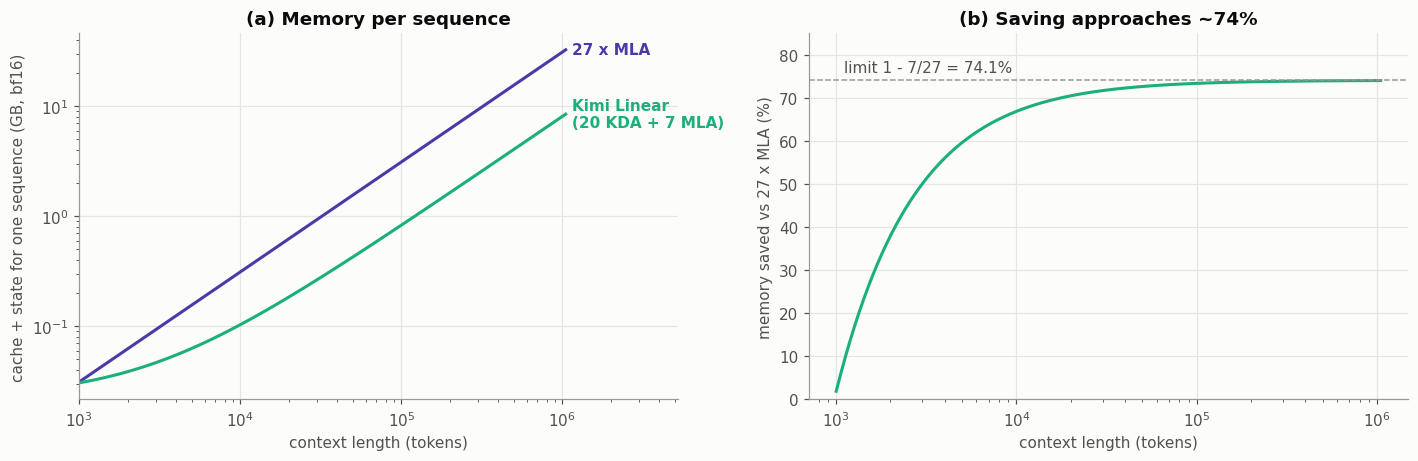

at 1,048,576 tokens: 27 x MLA 32.6 GB vs hybrid 8.5 GB -> 74.0% saved


In [21]:
pattern = ["MLA" if i in (4, 8, 12, 16, 20, 24, 27) else "KDA" for i in range(1, 28)]
print("layer types:", " ".join("M" if p == "MLA" else "k" for p in pattern), f"  ({pattern.count('KDA')} KDA, {pattern.count('MLA')} MLA)")

ctx = torch.logspace(3, math.log10(2**20), 120)         # 1K ... 1M (= 2^20, Kimi Linear's max context)
mla_cache_per_token = 512 + 64                                # latent + decoupled key dims, per MLA layer
kda_fixed = 32 * 128 * 128 + 3 * 3 * 4096                     # recurrent state + conv states, per KDA layer
bytes_per = 2
full_mla = 27 * mla_cache_per_token * ctx * bytes_per / 1e9
hybrid = (pattern.count("MLA") * mla_cache_per_token * ctx + pattern.count("KDA") * kda_fixed) * bytes_per / 1e9

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3))
ax1.plot(ctx, full_mla, color=VIOLET); ax1.plot(ctx, hybrid, color=AQUA)
ax1.text(ctx[-1] * 1.1, full_mla[-1], "27 x MLA", color=VIOLET, va="center", fontweight="bold")
ax1.text(ctx[-1] * 1.1, hybrid[-1], "Kimi Linear\n(20 KDA + 7 MLA)", color=AQUA, va="center", fontweight="bold")
ax1.set_xscale("log"); ax1.set_yscale("log"); ax1.set_xlim(1e3, 2**20 * 5)
ax1.set_xlabel("context length (tokens)"); ax1.set_ylabel("cache + state for one sequence (GB, bf16)")
ax1.set_title("(a) Memory per sequence")
ratio = 1 - hybrid / full_mla
ax2.plot(ctx, ratio * 100, color=AQUA)
ax2.axhline((1 - 7 / 27) * 100, color=MUTED, linestyle="--", linewidth=1)
ax2.text(1.1e3, (1 - 7 / 27) * 100 + 2, f"limit 1 - 7/27 = {(1 - 7 / 27):.1%}", color=INK_2)
ax2.set_xscale("log"); ax2.set_ylim(0, 85)
ax2.set_xlabel("context length (tokens)"); ax2.set_ylabel("memory saved vs 27 x MLA (%)")
ax2.set_title("(b) Saving approaches ~74%")
plt.tight_layout(); plt.show()
print(f"at {ctx[-1]:,.0f} tokens: 27 x MLA {full_mla[-1]:.1f} GB vs hybrid {hybrid[-1]:.1f} GB -> {ratio[-1]:.1%} saved")

For the released 27-layer config the saving approaches $1 - 7/27 \approx 74\%$. A perfectly uniform 3:1 stack would approach $1 - 1/4 = 75\%$, which is the paper's *"reducing KV cache usage by up to 75%"*. Less memory per sequence allows bigger decoding batches. Combined with KDA's constant per-token cost, the paper measures a **6.3× faster time-per-output-token than MLA at 1M context (1.84 ms vs 11.48 ms)**, and reports that the hybrid *"outperforms full MLA with a sizeable margin across all evaluated tasks"* (e.g. RULER 84.3 vs 81.3).

**The same design at frontier scale.** Moonshot's **Kimi K3** keeps the recipe. Its released `config.json` lists 93 layers: 69 KDA and 24 MLA (layers 4, 8, …, 92 and 93), with 96 KDA heads of dimension 128, MLA still without positional encoding (`mla_use_nope: true`) and now with an output gate. Two KDA details changed:
* `use_full_rank_gate: true`. The decay projection is full-rank instead of the low-rank $W^\uparrow W^\downarrow$ used in Kimi Linear.
* `gate_lower_bound: -5.0`. In the reference FLA code, a lower bound switches the gate to $g = -5\,\sigma\big(e^{A_{\log}}(f + b_{dt})\big)$, so the per-step decay can never fall below $e^{-5} \approx 0.0067$. This caps how fast any channel can forget in a single step. It corresponds to the `lower_bound` option of `fla/layers/kda.py`.

Source: https://huggingface.co/moonshotai/Kimi-K3 (`config.json`, `text_config`).

# 9. A small experiment: multi-query associative recall

**Multi-query associative recall (MQAR)** is the standard synthetic probe for recall in linear-attention models (the Kimi Linear paper uses it too, in §5.1). The model reads 16 random key→value token pairs and then a series of keys, and for each key it must output the value that followed it earlier. We train 2-layer models (width 64, 2 heads of 32) that are **identical except for the update rule**, which we select with the layer's `gate` switch:

| variant | update rule |
|---|---|
| `linear` | linear attention: $S_t = S_{t-1} + k_t v_t^\top$ |
| `none` | DeltaNet: delta rule, no decay |
| `gdn` | Gated DeltaNet: delta rule + one decay per head |
| `kda` | KDA: delta rule + per-channel decay |

Each variant is trained with **3 seeds**, and we report all of them. Toy experiments at this scale are noisy. A single seed can easily make any one variant look best or worst, which is why the paper's own synthetic experiments sweep learning rates (see the comparison below) and why its main comparisons use much larger models.

This takes about 15–20 minutes on a laptop CPU (15–19 minutes across runs on an Apple M4 Pro). Set `RUN_EXPERIMENT = False` to skip it.

In [22]:
RUN_EXPERIMENT = True

def make_mqar(batch, n_pairs=16, seq_len=64, vocab=256, generator=None):
    """Keys from the first half of the vocabulary, values from the second; queries are earlier keys, targets their values."""
    half = vocab // 2
    keys = torch.stack([torch.randperm(half - 1, generator=generator)[:n_pairs] + 1 for _ in range(batch)])
    vals = torch.randint(half, vocab, (batch, n_pairs), generator=generator)
    context = torch.stack([keys, vals], -1).reshape(batch, 2 * n_pairs)          # k1 v1 k2 v2 ...
    which = torch.randint(0, n_pairs, (batch, seq_len - 2 * n_pairs), generator=generator)
    x = torch.cat([context, torch.gather(keys, 1, which)], 1)
    y = torch.full_like(x, -100)                                                 # -100 = ignored by the loss
    y[:, 2 * n_pairs:] = torch.gather(vals, 1, which)
    return x, y

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps, self.weight = eps, nn.Parameter(torch.ones(dim))
    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

class TinyLM(nn.Module):
    def __init__(self, vocab, d_model, n_layers, n_heads, gate):
        super().__init__()
        self.emb = nn.Embedding(vocab, d_model)
        self.blocks = nn.ModuleList([nn.ModuleDict(dict(
            norm1=RMSNorm(d_model), mixer=KimiDeltaAttention(d_model, n_heads, d_model // n_heads, chunk_size=16, gate=gate),
            norm2=RMSNorm(d_model), mlp=nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(), nn.Linear(4 * d_model, d_model)),
        )) for _ in range(n_layers)])
        self.norm, self.head = RMSNorm(d_model), nn.Linear(d_model, vocab)
    def forward(self, x):
        h = self.emb(x)
        for blk in self.blocks:
            h = h + blk["mixer"](blk["norm1"](h))[0]                              # pre-norm residual blocks
            h = h + blk["mlp"](blk["norm2"](h))
        return self.head(self.norm(h))

def train_mqar(gate, seed, steps=1000, lr=3e-3, eval_every=100):
    torch.manual_seed(seed)
    model = TinyLM(vocab=256, d_model=64, n_layers=2, n_heads=2, gate=gate)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.1)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=steps, pct_start=0.1)
    x_val, y_val = make_mqar(512, generator=torch.Generator().manual_seed(1234))   # same held-out set for everyone
    curve = []
    for step in range(1, steps + 1):
        x, y = make_mqar(64)
        loss = F.cross_entropy(model(x).reshape(-1, 256), y.reshape(-1))
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
        if step % eval_every == 0:
            with torch.no_grad():
                pred, mask = model(x_val).argmax(-1), y_val != -100
                curve.append((pred[mask] == y_val[mask]).float().mean().item())
    return curve

variants = {"linear": "linear attention", "none": "DeltaNet", "gdn": "Gated DeltaNet", "kda": "KDA"}
results = {}
if RUN_EXPERIMENT:
    t_start = time.time()
    for gate in variants:
        results[gate] = [train_mqar(gate, seed) for seed in range(3)]
        print(f"{variants[gate]:>16}: final accuracy per seed = {[round(c[-1], 3) for c in results[gate]]}   ({time.time() - t_start:.0f}s elapsed)")

linear attention: final accuracy per seed = [0.999, 0.999, 1.0]   (100s elapsed)


        DeltaNet: final accuracy per seed = [0.991, 0.993, 0.984]   (337s elapsed)


  Gated DeltaNet: final accuracy per seed = [0.942, 0.133, 0.914]   (612s elapsed)


             KDA: final accuracy per seed = [0.726, 0.092, 0.09]   (891s elapsed)


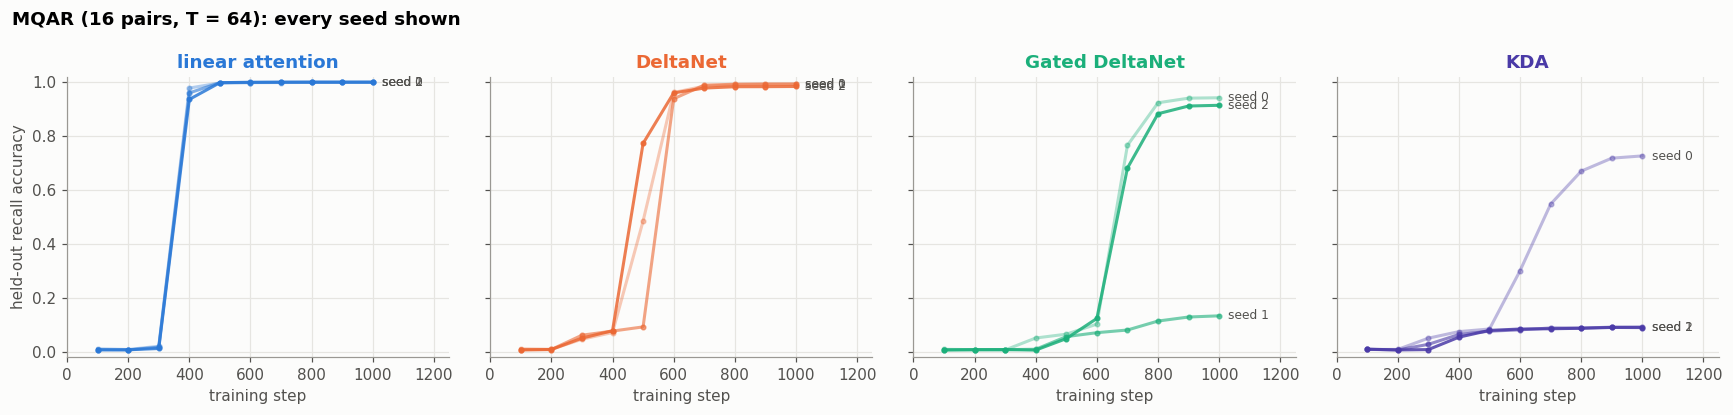

In [23]:
if results:
    steps_axis = [100 * (i + 1) for i in range(len(next(iter(results.values()))[0]))]
    colors = {"linear": BLUE, "none": ORANGE, "gdn": AQUA, "kda": VIOLET}
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
    for ax, (gate, curves) in zip(axes, results.items()):
        for seed, c in enumerate(curves):
            ax.plot(steps_axis, c, color=colors[gate], alpha=0.35 + 0.25 * seed, marker="o", markersize=3)
            ax.text(steps_axis[-1] + 30, c[-1], f"seed {seed}", color=INK_2, fontsize=8, va="center")
        ax.set_title(variants[gate], color=colors[gate])
        ax.set_xlabel("training step"); ax.set_xlim(0, 1250); ax.set_ylim(-0.02, 1.02)
    axes[0].set_ylabel("held-out recall accuracy")
    fig.suptitle("MQAR (16 pairs, T = 64): every seed shown", x=0.01, ha="left", fontweight="bold")
    plt.tight_layout(); plt.show()

**What this does and does not show.** (Numbers refer to the run saved in this notebook.)

* **Linear attention and DeltaNet solve this task reliably.** With 16 pairs and two 32-dimensional heads, the memory is not overloaded and nothing ever needs to be forgotten, so the extra machinery has nothing to fix.
* **The gated variants are much less reliable at this scale.** In this run Gated DeltaNet solved the task on 2 of 3 seeds (94%, 91%, and one seed stuck at 13%). **KDA was the least reliable of the four**: one seed reached 73%, and the other two plateaued at 9%. Chance is about 0.8% (1 in 128 possible values), so those seeds learned only a small fraction of the pairs. We checked the kernel, the gate formula and the layer against the reference implementations, so this is a property of the setup, not a bug. A plausible reason is the reference Mamba-style initialization (§4): with a 32-dim head, roughly half of KDA's key channels start with half-lives of under ~10 tokens. That is a poor fit for a task that has to hold every pair for up to ~60 tokens, and a tiny model on a short budget may never learn its way out. Gating is a tool for *choosing what to forget*, and this task gives it nothing useful to do.
* **Compare with the paper's synthetic experiments** (Kimi Linear §5.1, Figure 4 below). Their models are as small as ours: 2 layers and 2 heads. On MQAR, KDA reaches ~93% within the first ~2K steps, while Gated DeltaNet is still at ~80% after 20K steps, and KDA holds up better as sequences grow. What differs is the training protocol: head dimension **128** (ours: 32), up to **20,000** steps (ours: 1,000), sequences of 256–2,048 tokens, a **grid search over four learning rates**, and reporting the **best-performing** run's training-accuracy curve (we report every seed's held-out accuracy at one learning rate). An LR sweep with best-run selection removes exactly the seed and initialization variance that dominates our run. Wider heads plausibly help too, because a 128-dim head has four times as many channels, and so many more long-lived ones at initialization.

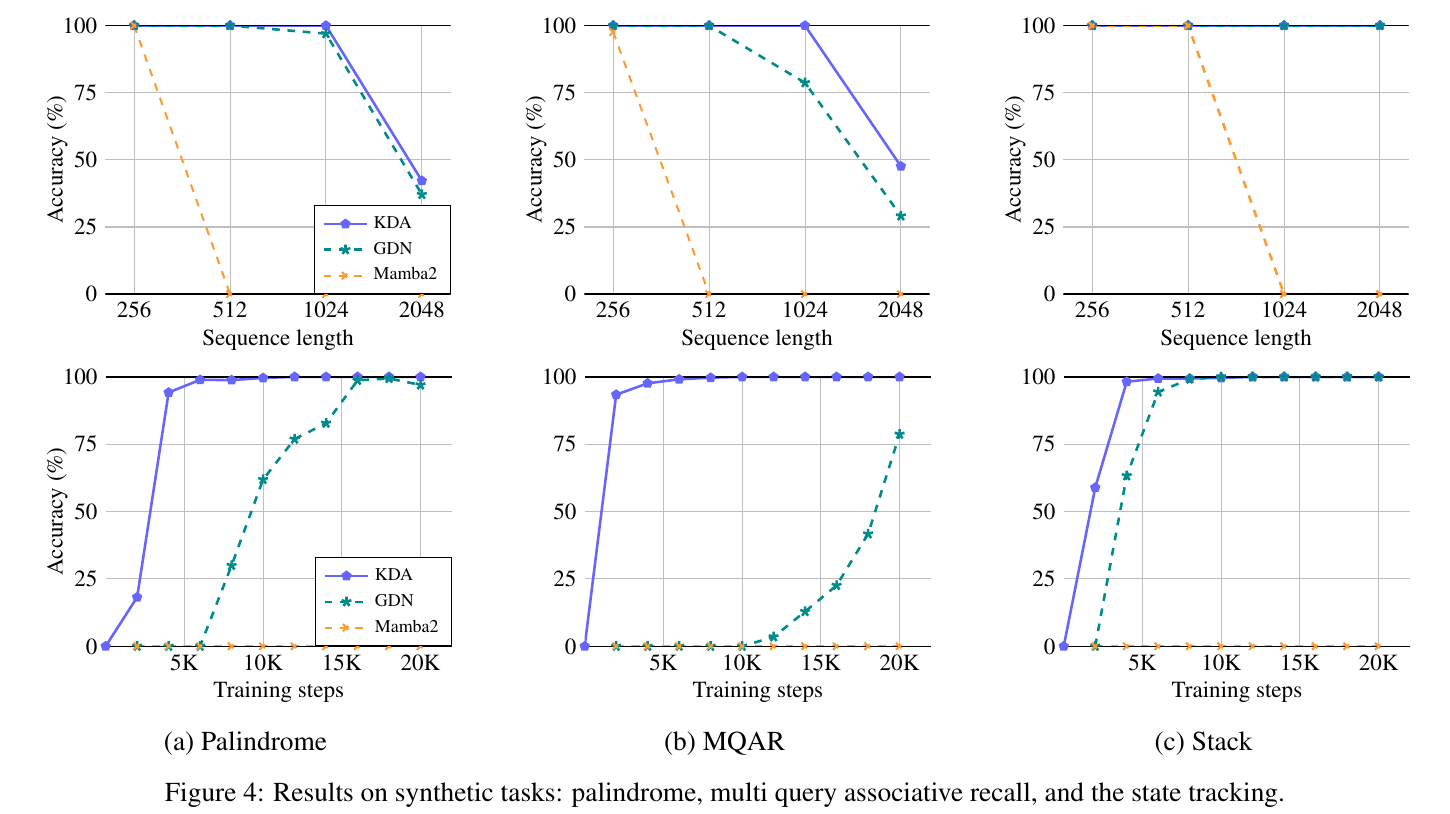

*Kimi Linear, Figure 4. Top: accuracy vs sequence length; bottom: accuracy vs training steps at length 1,024. Source: [arXiv:2510.26692](https://arxiv.org/abs/2510.26692), CC BY-NC-ND 4.0.*

* **This is not evidence against KDA.** As the comparison above shows, the paper's toy models are no bigger than ours. The gap comes from the training protocol (wider heads, 20× more steps, an LR sweep, best-run reporting). KDA's main results are on 1B+ parameter models trained on real data, where choosing what to forget matters. The experiment is shown here because a from-scratch layer should be checked by actually training it, and because an honest result under a fixed small budget teaches more than a tuned one.

While building this notebook, two bugs made the delta-rule variants fail completely on this task. Both are worth knowing about:
1. **No output norm.** Without the head-wise RMSNorm before `o_proj`, a delta-rule read ($\approx v \cdot q^\top k / \sqrt{d_k}$) is several times smaller than linear attention's unnormalized sum, and DeltaNet trained to ~1% accuracy instead of ~99%.
2. **Zero gate initialization.** With `A_log = dt_bias = 0`, every channel starts at $\alpha = e^{-\mathrm{softplus}(0)} \approx 0.5$, a half-life of one token, and KDA could not learn the task at all. The Mamba-style init above fixes it.

# Summary

| concept | equation / fact |
|---|---|
| state | $S \in \mathbb{R}^{d_k \times d_v}$ per head, fixed size (Kimi Linear: 32 heads × 128 × 128) |
| update | $S_t = (I - \beta_t k_t k_t^\top)\,\mathrm{Diag}(\alpha_t)\,S_{t-1} + \beta_t k_t v_t^\top$: **decay first**, then the delta correction |
| output | $o_t = S_t^\top q_t$, read **after** the update; $q$ scaled by $1/\sqrt{d_k}$ |
| delta rule | one SGD step on $\tfrac12\|S^\top k_t - v_t\|^2$ with learning rate $\beta_t$; erase-then-write |
| gate | $\log\alpha_t = -e^{A_{\log}}\,\mathrm{softplus}(W^\uparrow W^\downarrow x_t + b_{dt})$, **per key channel**, low-rank |
| relation to DPLR | transition $\mathrm{Diag}(\alpha) - \beta k (k \odot \alpha)^\top$: DPLR with both low-rank vectors tied to $k$, ~2× faster kernels |
| training | chunkwise: WY representation + UT transform inside chunks, state passed between chunks; use $e^{g_r - g_i}$, never $\gamma$ and $1/\gamma$ separately |
| architecture | Kimi Linear: 3 KDA : 1 MLA (NoPE), up to ~75% less KV cache, 6.3× faster TPOT at 1M context |

### Implementation checklist (each item is a bug someone has shipped)
1. Gates are **log** decays ($g \le 0$); pass $g$, not $\alpha$.
2. Apply $\mathrm{Diag}(\alpha_t)$ **before** the delta correction, and read the output from the **updated** state.
3. L2-normalize $q$ and $k$ (after the short conv + SiLU), never $v$.
4. In the chunkwise form, $A$ excludes the diagonal but $A^{qk}$ includes it. The cumulative decay resets at every chunk boundary.
5. Keep the head-wise output norm and the Mamba-style gate initialization. Without them the delta-rule variants may not train at all (§9).

### Further reading
* **Songlin Yang, "DeltaNet Explained"** (three parts), by the author of DeltaNet and Gated DeltaNet. This is the best companion to this notebook. [Part I](https://sustcsonglin.github.io/blog/2024/deltanet-1) covers linear attention as an RNN and the delta rule as gradient descent. [Part II](https://sustcsonglin.github.io/blog/2024/deltanet-2) covers the chunkwise algorithm: why a plain parallel scan fails, the WY representation and the UT transform, with diagrams. [Part III](https://sustcsonglin.github.io/blog/2024/deltanet-3) covers the architecture: why L2 norm, the output norm, short convolutions, and hybrids.
* **Kimi Linear tech report**, especially §3 (the chunkwise algorithm), §6.2 (KDA as a constrained DPLR) and Table 7 (the update rules of the whole family as online-learning objectives). https://arxiv.org/abs/2510.26692
* **flash-linear-attention**: `fla/ops/kda/naive.py` is a short, readable reference that this notebook's kernels match to float32 precision, and `fla/layers/kda.py` is the production layer. https://github.com/fla-org/flash-linear-attention